# Predicting the severity of road traffic accidents in Lithuania

Deep Learning Systems (INF4039), individual project

Author: Oleksandr Klepachevskyi, IF2200097 | November 2026

Data: Lithuanian Police Department, [data.gov.lt dataset #509](https://data.gov.lt/datasets/509/) (CC BY 4.0)

Note on running: in Google Colab use Runtime -> Run all. The notebook downloads the data by itself (about 456 MB) and installs KerasTuner. A full run takes around 1-1.5 hours on CPU (most of the time is the Transformer tuning), with a GPU runtime it is faster. All outputs are already saved in the notebook.

# Content
1. Dataset description
2. Hypothesis
3. Goal
4. Objectives
5. Data preparation (cleaning, missing values, outliers, features)
6. Exploratory data analysis (histograms, scatter plots, correlations)
7. Preparing the data for the models
8. Machine learning algorithm - random forest
9. 1st neural network - multilayer perceptron (MLP)
10. 2nd neural network - Transformer for tabular data
11. Comparison of the best models
12. Conclusions

# 1. Dataset description

I used the open dataset of the Lithuanian Police Department: *Eismo įvykių, įvykusių Lietuvos Respublikoje, kurių metu žuvo ir (ar) buvo sužeisti žmonės, duomenys* (road traffic accidents in Lithuania where people were killed or injured).

| | |
|---|---|
| Source | Lithuanian open data portal, https://data.gov.lt/datasets/509/ |
| Publisher | Police Department under the Ministry of the Interior |
| License | CC BY 4.0 |
| Period | 2013-2025, one JSON file per year (updated every July). I used the last 5 years, 2021-2025 |
| Format | nested JSON - one record is one accident, and inside it there is a list of participants and a list of vehicles |
| Size | 5 files, about 456 MB: 108 918 accidents, 189 890 participants, 173 943 vehicles |
| Used in the project | 14 049 injury accidents (police flag `iskaitinis = 1`, at least one person killed or injured): 11 247 for training (2021-2024) and 2 802 for testing (2025) |

For every accident there are 52 accident fields, 28 participant fields and 17 vehicle fields. The main groups:

| Group | Examples (original name - meaning) |
|---|---|
| When | `dataLaikas` - date and time |
| Where | `savivaldybe` municipality, `kelioReiksme` road class, `leistinasGreitis` speed limit, `sankryzosTipas` junction type, `ilguma`/`platuma` coordinates (LKS-94) |
| Conditions | `meteoSalygos` weather, `dangosBukle` road surface, `parosMetas` daylight, `kelioApsvietimas` street lighting, `kelioGatvesKreive` road geometry |
| What happened | `rusis` accident type (collision, pedestrian hit, rollover...), `schema1` collision scheme (head-on, run-off-road...) |
| Participants | role (driver, passenger, pedestrian, cyclist...), age, gender, sobriety, seat belt / helmet, driving experience, culprit, traffic rule violations |
| Vehicles | category (car, truck, bus, motorcycle...), country of registration, impact side |
| Outcome | number killed / injured, condition of each person (killed, injured, hospitalised), injury severity |

Why I chose this dataset: road safety is a real problem, and the EU wants to halve road deaths and serious injuries by 2030. If we know which circumstances make an accident fatal or serious, it helps to decide where to act (lighting, speed limits, pedestrian crossings, drunk driving control). The data is official and recent, it is big enough for neural networks (around 14 000 examples), and it needed a lot of real cleaning (nested structure, Lithuanian categories, missing and wrong values).

### Prediction task - binary classification

The target `severe` is made from the outcome fields of the participants:

| `severe` | Meaning | Accidents |
|---|---|---|
| 1 - killed or seriously injured (KSI) | at least one person killed at the scene (`Žuvo`), died of injuries (`Mirė nuo sužalojimų`), treated in hospital as an in-patient (`Gydomas stacionare`) or with a serious health impairment (`Sunkus sveikatos sutrikdymas`) | 4 079 (29 %), 626 of them fatal |
| 0 - slight | all injured people had only slight injuries (out-patient treatment) | 9 970 (71 %) |

KSI (killed or seriously injured) is the usual indicator in road safety statistics. As inputs I only use things that are known at the scene of the accident. All fields that describe the outcome are removed (see 5.5).

# 2. Hypothesis

Main hypothesis (H1): whether an injury accident in Lithuania ends with a death or a serious injury can be predicted from the circumstances recorded at the scene (road, environment, time, who was involved and how they behaved). A model trained on 2021-2024 should work clearly better than chance on the unseen year 2025: ROC-AUC >= 0.70 on the 2025 test set (0.5 = random guessing, 1.0 = perfect).

Second hypothesis (H2): severity depends on combinations of factors (for example pedestrian + darkness + high speed limit). Neural networks - a multilayer perceptron and a Transformer for tabular data - can learn such combinations, so they should be better than a classical machine learning model (random forest) trained on the same data. I compare them by ROC-AUC and F1 of the severe class on 2025.

Supporting hypotheses (tested in the EDA, section 6.6). The share of severe accidents is higher when:

| | Factor |
|---|---|
| H1a | a vulnerable road user is involved (pedestrian, cyclist, motorcycle/moped rider or e-scooter rider) |
| H1b | the speed limit is 70 km/h or more (roads outside towns) |
| H1c | it is dark and there are no street lights |
| H1d | the culprit was intoxicated (alcohol or drugs) |
| H1e | someone in a vehicle did not wear a seat belt |

How I decide:

| Hypothesis | Accepted if |
|---|---|
| H1 | the best model has ROC-AUC >= 0.70 on the 2025 test set |
| H2 | the best neural network has higher ROC-AUC on 2025 than the random forest and the difference is bigger than random variation (the 95 % bootstrap confidence interval of the difference does not include 0) |
| H1a-H1e | chi-square test p < 0.05 and risk ratio > 1 |

# 3. Goal

To build and compare machine learning and deep learning models that predict if a road accident with injuries in Lithuania is severe (killed or seriously injured), using the police data from 2021-2025, and to find which circumstances are most connected with severe outcomes.

# 4. Objectives

1. Download the 2021-2025 data from data.gov.lt and flatten the nested JSON (accidents, participants, vehicles).
2. Clean the data: duplicates, wrong dates, strings, invalid values, outliers and missing values; build the target and features without leakage; translate the categories to English.
3. Explore the data: distributions, severity rates, scatter plots, correlations; test H1a-H1e.
4. Train one classical ML model (random forest) and analyse its parameters.
5. Train the 1st neural network - multilayer perceptron (Keras) - and analyse its hyperparameters (one at a time + KerasTuner).
6. Train the 2nd neural network - Transformer for tabular data (FT-Transformer, Keras) - and analyse its hyperparameters.
7. Check accuracy on the training and test sets, compare the best models (ROC-AUC, PR-AUC, accuracy / error rate, balanced accuracy, F1, confusion matrices, ROC curves) and test the differences statistically.
8. Make conclusions: accept or reject H1 and H2 and find the most important risk factors.

# 5. Data preparation

## 5.0 Libraries and settings

Colab already has pandas, scikit-learn, TensorFlow/Keras and matplotlib. I only need to install KerasTuner for the hyperparameter search in chapters 9-10.

In [1]:
# install keras-tuner if it is not installed (colab doesn't have it)
# keras-tuner also needs tensorboard
try:
    import keras_tuner, tensorboard
except ImportError:
    %pip install -q keras-tuner tensorboard

In [2]:
import json
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)        # hide deprecation warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)    # keras-tuner prints a lot of these
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

RANDOM_STATE = 42                     # same seed everywhere so results can be repeated
YEARS = [2021, 2022, 2023, 2024, 2025]
TEST_YEAR = 2025                      # train on 2021-2024, test on 2025

# folders for raw and cleaned data
DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
OUT_DIR = DATA_DIR / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# plot style (blue = slight, orange = severe)
BLUE, ORANGE, MUTED, GRID, INK2 = "#2a78d6", "#eb6834", "#898781", "#e1e0d9", "#52514e"
AQUA, VIOLET = "#1baf7a", "#6250d6"
CLASS_COLORS = {0: BLUE, 1: ORANGE}
CLASS_NAMES = {0: "Slight", 1: "Severe (KSI)"}
DIVERGING = mcolors.LinearSegmentedColormap.from_list("blue_gray_red", ["#1c5cab", "#f0efec", "#c62f2e"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False, "figure.dpi": 110,
})

## 5.1 Download the raw data

One JSON file per year from data.gov.lt. The files are saved in `data/raw/`, so they are downloaded only once (about 456 MB).

In [3]:
# every year has its own file id on data.gov.lt (from the dataset page, tab "Ištekliai")
DISTRIBUTION_IDS = {2021: 10856, 2022: 14438, 2023: 15652, 2024: 17389, 2025: 19566}
URL = "https://data.gov.lt/datasets/509/distribution/{}/download/"

for year in YEARS:
    path = RAW_DIR / f"road_accidents_{year}.json"
    if not path.exists():                                   # download only if we don't have the file yet
        print(f"Downloading {year} ...")
        urllib.request.urlretrieve(URL.format(DISTRIBUTION_IDS[year]), path)
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")

road_accidents_2021.json: 96.1 MB
road_accidents_2022.json: 95.3 MB
road_accidents_2023.json: 101.1 MB
road_accidents_2024.json: 90.1 MB
road_accidents_2025.json: 73.3 MB


## 5.2 Load and flatten the nested JSON

Every accident record has two lists inside (participants and vehicles). I flatten them into three tables that are linked by the police registration code `registrokodas`:
* `acc_raw` - one row per accident
* `part_raw` - one row per participant
* `veh_raw` - one row per vehicle

In [4]:
# read all yearly files into one list of accidents
records = []
for year in YEARS:
    with open(RAW_DIR / f"road_accidents_{year}.json", encoding="utf-8") as f:
        year_records = json.load(f)
    for r in year_records:
        r["file_year"] = year               # remember from which file it came
    records.extend(year_records)

# json_normalize makes flat tables from the nested json:
#  - accidents: one row per accident (without the two nested lists)
#  - participants / vehicles: one row per person / vehicle + accident code to link them
acc_raw = pd.json_normalize(records, max_level=0).drop(columns=["eismoDalyviai", "eismoTranspPreimone"])
part_raw = pd.json_normalize(records, record_path="eismoDalyviai", meta=["registrokodas"])
veh_raw = pd.json_normalize(records, record_path="eismoTranspPreimone", meta=["registrokodas"])
del records                                  # free memory, the list is big

print(f"accidents:    {acc_raw.shape}")
print(f"participants: {part_raw.shape}")
print(f"vehicles:     {veh_raw.shape}")

accidents:    (108918, 51)
participants: (189890, 29)
vehicles:     (173943, 18)


I also save the three flat tables as CSV files in `data/raw/` (`raw_accidents.csv`, `raw_participants.csv`, `raw_vehicles.csv`), so the raw data can be opened in Excel. The values are not changed, only list fields (for example several weather conditions) are joined with `; `.

In [5]:
def lists_to_text(table):
    # csv can't store lists, so join them with "; "
    table = table.copy()
    for col in table.columns:
        if table[col].map(lambda v: isinstance(v, list)).any():
            table[col] = table[col].map(lambda v: "; ".join(map(str, v)) if isinstance(v, list) else v)
    return table

for name, table in [("raw_accidents", acc_raw.drop(columns="file_year")), ("raw_participants", part_raw), ("raw_vehicles", veh_raw)]:
    path = RAW_DIR / f"{name}.csv"
    lists_to_text(table).to_csv(path, index=False, encoding="utf-8-sig")    # utf-8-sig so lithuanian letters work in excel
    print(f"{path.name}: {table.shape[0]} rows x {table.shape[1]} columns, {path.stat().st_size / 1e6:.1f} MB")

raw_accidents.csv: 108918 rows x 50 columns, 51.7 MB


raw_participants.csv: 189890 rows x 29 columns, 35.3 MB


raw_vehicles.csv: 173943 rows x 18 columns, 21.1 MB


In [6]:
# one accident (transposed so it's easier to read)
acc_raw.iloc[[0]].T.head(52)

,0
registrokodas,07-21-9540806
dataLaikas,2021-01-01 01:20
registravimoData,2021-01-01 04:21
paskutinioRedagavimoLaikas,2021-01-03 10:54
iskaitinis,0
rusis,Kiti eismo įvykiai
schema1,Nuvažiavimai nuo kelio
schema2,Nuvažiavimai nuo kelio į dešinę tiesiame ruože
dalyviuSkaicius,1.0
zuvusiuSkaicius,0


In [7]:
# accidents per file and how many have injured or killed people
summary = acc_raw.groupby("file_year").agg(
    accidents=("registrokodas", "size"),
    injury_accidents=("iskaitinis", "sum"),
    killed=("zuvusiuSkaicius", "sum"),
    injured=("suzeistuSkaicius", "sum"),
)
summary.loc["Total"] = summary.sum()
summary

,accidents,injury_accidents,killed,injured
file_year,,,,
2021,23707,2782,147,3179
2022,23520,2857,120,3344
2023,24240,2808,160,3209
2024,21115,2799,124,3147
2025,16336,2809,138,3268
Total,108918,14055,689,16147


## 5.3 Duplicates, study period, injury accidents, cleaning strings

In [8]:
def normalise_strings(df):
    # remove extra spaces in all text columns ('Sutemos ' -> 'Sutemos'),
    # otherwise the same category is counted twice
    df = df.copy()
    for col in df.columns:
        if pd.api.types.is_object_dtype(df[col]) or pd.api.types.is_string_dtype(df[col]):
            mask = df[col].map(lambda v: isinstance(v, str))
            df.loc[mask, col] = df.loc[mask, col].map(lambda s: " ".join(s.split()))
    return df

acc = normalise_strings(acc_raw)
part_all = normalise_strings(part_raw)
veh_all = normalise_strings(veh_raw)

log = [("Raw accident records", len(acc))]          # log how many rows are left after each step

# 1) duplicates (same accident could be in two files)
acc = acc.drop_duplicates(subset="registrokodas")
log.append(("After removing duplicate registration codes", len(acc)))

# 2) parse dates and keep 2021-2025
acc["datetime"] = pd.to_datetime(acc["dataLaikas"], errors="coerce")
outside = acc[~acc["datetime"].dt.year.between(YEARS[0], YEARS[-1])]
print("Records dated outside 2021-2025 (late registrations / data-entry errors):")
print(outside["datetime"].dt.year.value_counts().sort_index().to_string())
acc = acc[acc["datetime"].dt.year.between(YEARS[0], YEARS[-1])]
log.append(("After keeping dates 2021-01-01 ... 2025-12-31", len(acc)))

# 3) only injury accidents (iskaitinis = 1 means someone killed or injured)
acc = acc[acc["iskaitinis"] == 1].copy()
log.append(("After keeping injury accidents (iskaitinis = 1)", len(acc)))

# keep only participants and vehicles of these accidents
acc = acc.set_index("registrokodas", drop=False)
part = part_all[part_all["registrokodas"].isin(acc.index)].copy()
veh = veh_all[veh_all["registrokodas"].isin(acc.index)].copy()

pd.DataFrame(log, columns=["step", "rows"])

Records dated outside 2021-2025 (late registrations / data-entry errors):
datetime
1899     1
2015     7
2016     4
2019     1
2020    69


,step,rows
0,Raw accident records,108918
1,After removing duplicate registration codes,108918
2,After keeping dates 2021-01-01 ... 2025-12-31,108836
3,After keeping injury accidents (iskaitinis = 1),14049


## 5.4 Target variable `severe`

In [9]:
# outcome of every person (only for the target, NOT used as features)
part["killed"] = part["bukle"].isin(["Žuvo", "Mirė nuo sužalojimų"])                 # killed / died of injuries
part["hospitalised"] = part["detaliBukle"].eq("Gydomas stacionare")                  # stayed in hospital
part["serious_injury"] = part["suzalojimoMastas"].eq("Sunkus sveikatos sutrikdymas")  # serious injury
part["ksi"] = part["killed"] | part["hospitalised"] | part["serious_injury"]

# accident is severe if at least one person is KSI
acc["severe"] = part.groupby("registrokodas")["ksi"].any().reindex(acc.index, fill_value=False).astype(int)

# check: does the police death counter agree with the target?
check = pd.crosstab(acc["zuvusiuSkaicius"] > 0, acc["severe"],
                    rownames=["accident has killed > 0"], colnames=["severe from participants"])
display(check)

# if the counter says someone died but nobody is marked killed -> trust the counter
inconsistent = (acc["zuvusiuSkaicius"] > 0) & (acc["severe"] == 0)
acc.loc[inconsistent, "severe"] = 1
print(f"Fixed {inconsistent.sum()} inconsistent records")
print(acc["severe"].value_counts().rename(index=CLASS_NAMES).to_string())
print(f"Severe share: {acc['severe'].mean():.1%}")

severe from participants,0,1
accident has killed > 0,,
False,9970,3453
True,0,626


Fixed 0 inconsistent records
severe
Slight          9970
Severe (KSI)    4079
Severe share: 29.0%


## 5.5 Leakage control

The model should not see information that is known only after the outcome, otherwise it would just "read" the answer. So these fields are not used as features:

| Field(s) | Why removed |
|---|---|
| `zuvusiuSkaicius`, `zuvVaiku`, `suzeistuSkaicius`, `suzeistaVaiku`, participant `bukle`, `detaliBukle`, `suzalojimoMastas` | this is the outcome itself (used only to build the target) |
| `iskaitinis` | constant after filtering |
| participant `teisenosStadijaBusena` (criminal pre-trial investigation) | a criminal case is opened because someone was badly injured or killed |
| participant `oroPagalves` (airbags), vehicle `apgadinimai`, `apgadinimaiKita` (damage) | consequences of the crash, recorded after it |
| `registravimoData`, `paskutinioRedagavimoLaikas` | registration and last edit dates - serious cases are edited for longer |
| `registrokodas`, `ivykioVieta`, `gatve`, `namas`, `kelioPavadinimas`, `atstumas`, police units, car make/model, ids | ids or free text with thousands of values |
| `pagaminimoMetai` (vehicle year), `pilietybe`, `girtumasPromilemis` | more than 85 % missing; sobriety is covered by other fields |

Everything else is turned into features below. In section 7.4 I check how much the score would change if some of these fields were used.

## 5.6 Participant-level cleaning and features

The participant table has one row per person. First I clean wrong values, then I aggregate the participants to one row per accident:
* who was involved: pedestrians, cyclists, motorcycles/mopeds, e-scooters, passengers, children (< 14), seniors (65+), number of vulnerable road users and the age of the oldest one, number of people in vehicles, oldest participant;
* behaviour and protection: anyone without a seat belt / helmet, number of intoxicated participants, intoxicated pedestrian or cyclist;
* the culprit (the person the police found at fault): role, age, gender, novice driver, no licence, fled the scene, and what rule they broke.

After the interim presentation I added the counts of vulnerable road users, occupants and intoxicated people, the oldest ages, and trucks / buses / impact side (5.7). On the validation year this improved the ROC-AUC of a simple model by about 0.007.

In [10]:
# participant roles lithuanian -> english
ROLE_EN = {
    "Automobilio vairuotojas": "Car driver",
    "Keleivis": "Passenger",
    "Pėsčiasis": "Pedestrian",
    "Dviračio vairuotojas": "Cyclist",
    "Motociklo vairuotojas": "Motorcyclist",
    "Mopedo vairuotojas": "Moped rider",
    "Keturračio motociklo vairuotojas": "Quad rider",
    "Lengvojo keturračio motociklo vairuotojas": "Quad rider",
    "Elektrinio paspirtuko vairuotojas": "E-scooter rider",
    "Traktoriaus vairuotojas": "Other driver",
    "Kitos transporto priemonės vairuotojas": "Other driver",
    "Asmuo, kuris moko vairuoti": "Other",
    "Vadeliotojas": "Other",
    "Kiti": "Other",
}
MOTOR_DRIVERS = ["Car driver", "Motorcyclist", "Other driver"]
VULNERABLE = ["Pedestrian", "Cyclist", "Motorcyclist", "Moped rider", "Quad rider", "E-scooter rider"]
INTOXICATED = ["Neblaivus", "Neblaivus ir apsvaigęs",
               "Apsvaigęs nuo narkotinių, psichotropinių ar kitų psichiką veikiančių medžiagų"]

part["role"] = part["kategorija"].map(ROLE_EN).fillna("Unknown")
print("Unmapped roles:", sorted(set(part["kategorija"].dropna()) - set(ROLE_EN)))

# --- invalid values ---
# age > 100, negative age or car/motorcycle driver younger than 10 = data error
bad_age = (part["amzius"] > 100) | (part["amzius"] < 0) | (part["role"].isin(MOTOR_DRIVERS) & (part["amzius"] < 10))
# driving experience can't be longer than age - 14
bad_exp = (part["vairavimoStazas"] > part["amzius"] - 14) | (part["vairavimoStazas"] > 80)
print(f"Invalid ages set to NaN: {bad_age.sum()} (e.g. motor-vehicle drivers younger than 10: "
      f"{sorted(part.loc[bad_age, 'amzius'].unique())})")
print(f"Invalid driving experience set to NaN: {bad_exp.sum()} (experience longer than age - 14 years)")
part.loc[bad_age, "amzius"] = np.nan
part.loc[bad_exp, "vairavimoStazas"] = np.nan

# --- who was involved (True/False for every person) ---
part["is_pedestrian"] = part["role"].eq("Pedestrian")
part["is_cyclist"] = part["role"].eq("Cyclist")
part["is_ptw"] = part["role"].isin(["Motorcyclist", "Moped rider", "Quad rider"])   # motorcycles, mopeds, quads
part["is_escooter"] = part["role"].eq("E-scooter rider")
part["is_passenger"] = part["role"].eq("Passenger")
part["is_occupant"] = part["role"].isin(["Car driver", "Passenger"])                # people inside a vehicle
part["is_vru"] = part["role"].isin(VULNERABLE)                                       # vulnerable road user
part["vru_age"] = part["amzius"].where(part["is_vru"])                               # age only if VRU
part["is_child"] = part["amzius"].lt(14)
part["is_senior"] = part["amzius"].ge(65)
part["unbelted"] = part["saugosDirzas"].eq("Neužsegtas")
part["no_helmet"] = part["saugosSalmoNaudojimas"].eq(0)
part["intoxicated"] = part["busena"].isin(INTOXICATED)
part["vru_intoxicated"] = part["is_vru"] & part["intoxicated"]

# one row per accident: max of a flag = at least one person, sum = count
who = part.groupby("registrokodas").agg(
    has_pedestrian=("is_pedestrian", "max"),
    has_cyclist=("is_cyclist", "max"),
    has_powered_two_wheeler=("is_ptw", "max"),
    has_escooter=("is_escooter", "max"),
    n_passengers=("is_passenger", "sum"),
    n_occupants=("is_occupant", "sum"),
    n_vru=("is_vru", "sum"),
    oldest_vru_age=("vru_age", "max"),
    oldest_participant_age=("amzius", "max"),
    has_child=("is_child", "max"),
    has_senior=("is_senior", "max"),
    any_unbelted=("unbelted", "max"),
    any_no_helmet=("no_helmet", "max"),
    n_intoxicated=("intoxicated", "sum"),
    vru_intoxicated=("vru_intoxicated", "max"),
)

# --- the culprit ---
# if more than one person is at fault, take the main one (KALTININKAS before GALIMAS_KALTININKAS)
cul = part[part["kaltininkas"].eq("Taip")].copy()
cul["priority"] = cul["dalyvioBusena"].map({"KALTININKAS": 0, "GALIMAS_KALTININKAS": 1}).fillna(2)
n_culprits = cul.groupby("registrokodas").size()
cul = cul.sort_values(["registrokodas", "priority", "dalyvisId"]).drop_duplicates("registrokodas")
cul = cul.set_index("registrokodas")
# violations are a list of lithuanian texts, join them and search for key words
violations = cul["dalyvioKetPazeidimai"].map(lambda v: " | ".join(v) if isinstance(v, list) else "")

culprit = pd.DataFrame({
    "culprit_role": cul["role"],
    "culprit_age": cul["amzius"],
    "culprit_gender": cul["lytis"].map({"Vyras": "Male", "Moteris": "Female"}),
    "culprit_novice": cul["vairavimoStazas"].lt(2),                                   # < 2 years of driving
    "culprit_unlicensed": cul["vairuotojoKvalifikacija"].eq("Neturi teisės vairuoti"),
    "culprit_fled": cul["pasisalino"].eq("Taip"),
    "culprit_speeding": violations.str.contains("greičio", case=False),               # "greitis" = speed
    "culprit_failed_to_yield": violations.str.contains("duoti kelią"),                # "give way"
    "culprit_wrong_lane": violations.str.contains("priešpriešinio eismo"),            # oncoming lane
    "culprit_fatigue_illness": violations.str.contains("Užmigimas|Pervargimas|Liga"), # fell asleep / tired / ill
})
culprit["n_culprits"] = n_culprits

print(f"Accidents with an identified culprit: {len(culprit)} of {len(acc)}")
culprit.head()

Unmapped roles: []
Invalid ages set to NaN: 6 (e.g. motor-vehicle drivers younger than 10: [np.float64(2.0), np.float64(5.0), np.float64(7.0), np.float64(9.0)])
Invalid driving experience set to NaN: 139 (experience longer than age - 14 years)


Accidents with an identified culprit: 13106 of 14049


,culprit_role,culprit_age,culprit_gender,culprit_novice,culprit_unlicensed,culprit_fled,culprit_speeding,culprit_failed_to_yield,culprit_wrong_lane,culprit_fatigue_illness,n_culprits
registrokodas,,,,,,,,,,,
07-21-9540814,Car driver,29.0,Female,False,False,False,True,False,False,False,1
07-21-9540958,Other driver,19.0,Male,True,False,False,False,True,False,False,1
07-21-9540968,Passenger,52.0,Male,False,False,False,False,False,False,False,1
07-21-9540990,Car driver,51.0,Male,False,False,False,False,False,False,False,1
07-21-9540996,Car driver,24.0,Male,False,False,False,True,False,False,False,1


## 5.7 Vehicle-level features

In [11]:
# heavy vehicles (buses, trucks > 3.5 t, trailers, tractors, trains) - much bigger mass
veh["is_heavy"] = veh["kategorija"].str.contains(
    r"Autobusas|Troleibusas|Krovininis automobilis, bendroji masė didesnė|puspriekabė (?:virš|nuo 3,5)|Traktorius|Bėginė|žemės ūkio",
    na=False)
veh["is_truck"] = veh["kategorija"].str.contains(r"Krovininis automobilis, bendroji masė didesnė|puspriekabė (?:virš|nuo 3,5)", na=False)
veh["is_bus"] = veh["kategorija"].str.contains(r"Autobusas|Troleibusas", na=False)
veh["is_foreign"] = veh["regValstybe"].notna() & veh["regValstybe"].ne("Lietuva")
# impact side is a list like ["Priekinis kairys"] (front-left)
impacts = veh["pirminiaiSmugiai"].map(lambda v: v if isinstance(v, list) else [])
veh["side_impact"] = impacts.map(lambda v: any(s.startswith("Šoninis") for s in v))      # side
veh["front_impact"] = impacts.map(lambda v: any(s.startswith("Priekinis") for s in v))   # front
veh["rear_impact"] = impacts.map(lambda v: any(s.startswith("Galinis") for s in v))      # rear

vehicles = veh.groupby("registrokodas").agg(
    has_heavy_vehicle=("is_heavy", "max"),
    has_truck=("is_truck", "max"),
    has_bus=("is_bus", "max"),
    has_foreign_vehicle=("is_foreign", "max"),
    any_side_impact=("side_impact", "max"),
    any_rear_impact=("rear_impact", "max"),
    n_front_impacts=("front_impact", "sum"),
)
print(veh.loc[veh["is_heavy"], "kategorija"].value_counts().to_string())

kategorija
Autobusas virš 5t.                                                                826
Krovininis automobilis, bendroji masė didesnė kaip 12 t                           699
Priekaba arba puspriekabė virš 10t.                                               376
Krovininis automobilis, bendroji masė didesnė kaip 3,5 t, ne didesnė kaip 12 t    148
Traktorius                                                                        132
Autobusas ne daugiau 5t.                                                           75
Priekaba arba puspriekabė nuo 3,5t. iki 10t.                                       46
Bėginė transporto priemonė                                                          9
Troleibusas                                                                         8
Kita žemės ūkio transporto priemonė                                                 7


## 5.8 Accident-level features and translation to English

I translate the Lithuanian categories to short English labels. Some fields are combined:
* light condition = daylight (`parosMetas`) + street lighting (`kelioApsvietimas`, which is filled only in the dark);
* road class is empty for city streets, so if there is no class but there is a street name, it is "Street (settlement)";
* municipality type: city municipality (7 biggest cities) or district municipality (towns and countryside);
* coordinates are converted from the Lithuanian grid LKS-94 (metres) to GPS latitude / longitude.

In [12]:
# translations lithuanian -> english
ACCIDENT_TYPE_EN = {
    "Susidūrimas": "Vehicle collision",
    "Užvažiavimas ant pėsčiojo": "Pedestrian hit",
    "Kiti eismo įvykiai": "Other",
    "Susidūrimas su dviračiu": "Bicycle collision",
    "Apvirtimas": "Rollover",
    "Susidūrimas su motociklu": "Motorcycle collision",
    "Užvažiavimas ant kliūties": "Obstacle hit",
    "Susidūrimas su stovinčia transporto priemone": "Parked vehicle hit",
    "Susidūrimas su mopedu": "Moped collision",
    "Užvažiavimas ant gyvūno": "Animal hit",
    "Susidūrimas su bėgine transporto priemone": "Rail vehicle collision",
}
SCHEME_EN = {
    "Kiti eismo įvykiai": "Other",
    "Užvažiavimas ant pėsčiojo, kai nėra perėjos": "Pedestrian, no crossing",
    "Užvažiavimas ant pėsčiojo pėsčiųjų perėjoje": "Pedestrian on crossing",
    "Kiti susidūrimai": "Other collision",
    "Susidūrimai judant ta pačia kryptimi": "Same direction",
    "Nuvažiavimai nuo kelio": "Run-off-road",
    "Susidūrimai sukant į kairę (apsisukant)": "Left turn / U-turn",
    "Susidūrimas sukant į dešinę": "Right turn",
    "Priešpriešiniai susidūrimai": "Head-on",
}
ROAD_CLASS_EN = {"Magistraliniai keliai": "Main road", "Krašto keliai": "National road",
                 "Rajoniniai keliai": "Regional road", "Vietiniai keliai": "Local road"}
SURFACE_TYPE_EN = {"Asfaltbetonis, cementbetonis": "Asphalt / concrete", "Žvyrkelis": "Gravel",
                   "Grindinys": "Paving stones", "Be dangos": "Unpaved"}
SURFACE_COND_EN = {"Sausa": "Dry", "Šlapia": "Wet", "Apsnigta": "Snowy", "Apledėjusi": "Icy", "Užteršta": "Contaminated"}
WEATHER_EN = {"Giedra": "Clear", "Apsiniaukę": "Overcast", "Lietus": "Rain", "Sniegas, kruša": "Snow / hail",
              "Pūga": "Snow / hail", "Lijundra": "Sleet / freezing rain", "Rūkas": "Fog / strong wind",
              "Stiprus vėjas": "Fog / strong wind"}
GEOMETRY_EN = {"Tiesus horizontalus ruožas": "Straight, level", "Horizontalus vingis": "Curve",
               "Tiesi nuokalnė": "Straight, downhill", "Tiesi įkalnė": "Straight, uphill",
               "Vingiuota nuokalnė": "Curve, slope", "Vingiuota įkalnė": "Curve, slope"}
JUNCTION_EN = {"NEREGULIUOJAMA": "Uncontrolled junction", "REGULIUOJAMA": "Signal-controlled junction",
               "PRIE_SANKRYZOS": "Near junction"}
LIGHT_EN = {("Diena", None): "Daylight", ("Sutemos", None): "Twilight",
            ("Tamsus paros metas", "Įjungtas"): "Dark, street lights on",
            ("Tamsus paros metas", "Neįjungtas"): "Dark, street lights off",
            ("Tamsus paros metas", "Neįrengtas"): "Dark, no street lights"}
COUNTY = {  # first word of the municipality name -> county
    **dict.fromkeys(["Alytaus", "Druskininkų", "Lazdijų", "Varėnos"], "Alytus"),
    **dict.fromkeys(["Kauno", "Birštono", "Jonavos", "Kaišiadorių", "Kėdainių", "Prienų", "Raseinių"], "Kaunas"),
    **dict.fromkeys(["Klaipėdos", "Kretingos", "Neringos", "Palangos", "Skuodo", "Šilutės"], "Klaipėda"),
    **dict.fromkeys(["Marijampolės", "Kalvarijos", "Kazlų", "Šakių", "Vilkaviškio"], "Marijampolė"),
    **dict.fromkeys(["Panevėžio", "Biržų", "Kupiškio", "Pasvalio", "Rokiškio"], "Panevėžys"),
    **dict.fromkeys(["Šiaulių", "Akmenės", "Joniškio", "Kelmės", "Pakruojo", "Radviliškio"], "Šiauliai"),
    **dict.fromkeys(["Tauragės", "Jurbarko", "Pagėgių", "Šilalės"], "Tauragė"),
    **dict.fromkeys(["Telšių", "Mažeikių", "Plungės", "Rietavo"], "Telšiai"),
    **dict.fromkeys(["Utenos", "Anykščių", "Ignalinos", "Molėtų", "Visagino", "Zarasų"], "Utena"),
    **dict.fromkeys(["Vilniaus", "Elektrėnų", "Šalčininkų", "Širvintų", "Švenčionių", "Trakų", "Ukmergės"], "Vilnius"),
}


def lks94_to_wgs84(northing, easting):
    # LKS-94 -> GPS: inverse transverse mercator (GRS80, central meridian 24 deg E, scale 0.9998)
    # input: lithuanian grid coordinates in metres, output: latitude and longitude
    a, f, k0, lon0, fe = 6378137.0, 1 / 298.257222101, 0.9998, np.radians(24.0), 500000.0
    e2 = f * (2 - f)
    ep2 = e2 / (1 - e2)
    m = northing / k0
    mu = m / (a * (1 - e2 / 4 - 3 * e2**2 / 64 - 5 * e2**3 / 256))
    e1 = (1 - np.sqrt(1 - e2)) / (1 + np.sqrt(1 - e2))
    phi1 = (mu + (3 * e1 / 2 - 27 * e1**3 / 32) * np.sin(2 * mu)
            + (21 * e1**2 / 16 - 55 * e1**4 / 32) * np.sin(4 * mu)
            + (151 * e1**3 / 96) * np.sin(6 * mu) + (1097 * e1**4 / 512) * np.sin(8 * mu))
    c1, t1 = ep2 * np.cos(phi1)**2, np.tan(phi1)**2
    n1 = a / np.sqrt(1 - e2 * np.sin(phi1)**2)
    r1 = a * (1 - e2) / (1 - e2 * np.sin(phi1)**2)**1.5
    d = (easting - fe) / (n1 * k0)
    lat = phi1 - (n1 * np.tan(phi1) / r1) * (d**2 / 2 - (5 + 3 * t1 + 10 * c1 - 4 * c1**2 - 9 * ep2) * d**4 / 24
                                              + (61 + 90 * t1 + 298 * c1 + 45 * t1**2 - 252 * ep2 - 3 * c1**2) * d**6 / 720)
    lon = lon0 + (d - (1 + 2 * t1 + c1) * d**3 / 6
                  + (5 - 2 * c1 + 28 * t1 - 3 * c1**2 + 8 * ep2 + 24 * t1**2) * d**5 / 120) / np.cos(phi1)
    return np.degrees(lat), np.degrees(lon)

In [13]:
def translate(series, mapping, name):
    # translate and print values that are missing in the dictionary
    out = series.map(mapping)
    unmapped = sorted(set(series.dropna()) - set(mapping))
    if unmapped:
        print(f"{name}: unmapped values -> {unmapped}")
    return out


df = pd.DataFrame(index=acc.index)          # main table, one row per accident
# --- time ---
df["datetime"] = acc["datetime"]
df["year"] = acc["datetime"].dt.year
df["month"] = acc["datetime"].dt.month
df["weekday"] = acc["datetime"].dt.dayofweek          # 0 = Monday
df["hour"] = acc["datetime"].dt.hour
df["is_weekend"] = df["weekday"].ge(5)

# --- what happened / where ---
df["accident_type"] = translate(acc["rusis"], ACCIDENT_TYPE_EN, "accident_type")
df["collision_scheme"] = translate(acc["schema1"], SCHEME_EN, "collision_scheme")
# same municipality is written differently in different years ("Trakų r. sav." vs "Trakų rajono sav.")
municipality = (acc["savivaldybe"].str.replace(r" r\. sav\.$", " rajono sav.", regex=True)
                                 .str.replace(r" m\. sav\.$", " miesto sav.", regex=True))
print(f"Municipality names: {acc['savivaldybe'].nunique()} spellings -> {municipality.nunique()} municipalities")
df["municipality"] = municipality
df["county"] = translate(municipality.str.split().str[0], COUNTY, "county")
city = acc["vietosSavivaldybeTipas"].map({"MIESTO_SAVIVALDYBE": "City", "SAVIVALDYBE": "District"})
df["municipality_type"] = city.fillna(municipality.str.contains("miesto").map({True: "City", False: "District"}))
# road class is empty for city streets -> "Street (settlement)" if there is a street name
df["road_class"] = translate(acc["kelioReiksme"], ROAD_CLASS_EN, "road_class").fillna(
    pd.Series(np.where(acc["gatve"].notna(), "Street (settlement)", None), index=acc.index, dtype=object))
df["speed_limit"] = acc["leistinasGreitis"].astype(float)
df["junction"] = translate(acc["sankryzosTipas"], JUNCTION_EN, "junction").fillna("Not at junction")
df["ped_crossing"] = acc["kelioElementas1"].eq("Pėsčiųjų perėja") | acc["kelioElementas2"].eq("Pėsčiųjų perėja")

# --- conditions ---
df["surface_type"] = translate(acc["dangosRusis"], SURFACE_TYPE_EN, "surface_type")
df["surface_condition"] = translate(acc["dangosBukle"], SURFACE_COND_EN, "surface_condition")
df["weather"] = translate(acc["meteoSalygos"], WEATHER_EN, "weather")
df["light_condition"] = [LIGHT_EN.get((p, l if isinstance(l, str) else None))
                         for p, l in zip(acc["parosMetas"], acc["kelioApsvietimas"])]
df["road_geometry"] = translate(acc["kelioGatvesKreive"], GEOMETRY_EN, "road_geometry")
df["guardrail"] = acc["atitvarai"].eq("Yra")
df["road_deficiency"] = acc["nuliamentisVeiksnys"].notna() | acc["kitiNuliamentysVeiksniai"].map(lambda v: len(v) > 0)

# --- behaviour and counts ---
df["culprit_intoxicated"] = acc[["neblaivusKaltininkai", "apsvaigeKaltininkai", "atsisakeTikrintisKaltininkai"]].eq("Taip").any(axis=1)
df["n_participants"] = acc["dalyviuSkaicius"]
df["n_vehicles"] = acc["tpSkaicius"]
df["northing"] = acc["ilguma"].astype(float)      # 'ilguma' is actually the LKS-94 northing
df["easting"] = acc["platuma"].astype(float)      # and 'platuma' is the easting

# join participant, culprit and vehicle features and the target (same index = accident code)
df = df.join(who).join(culprit).join(vehicles)
df["severe"] = acc["severe"]

print(df.shape)
df.head(3).T

Municipality names: 70 spellings -> 60 municipalities


(14049, 61)


registrokodas,07-21-9540814,07-21-9540958,07-21-9540968
datetime,2021-01-01 04:59:00,2021-01-05 14:40:00,2021-01-05 17:30:00
year,2021,2021,2021
month,1,1,1
weekday,4,1,1
hour,4,14,17
...,...,...,...
has_foreign_vehicle,False,True,False
any_side_impact,True,False,False
any_rear_impact,False,False,False
n_front_impacts,1,1,1


## 5.9 Invalid values (rule-based)

These checks use fixed rules and no statistics from the data, so I can apply them to the whole dataset before the train/test split.

| Variable | Rule | What I do |
|---|---|---|
| date | year outside 2021-2025 (one even from 1899) | removed in 5.3 |
| participant age | > 100, < 0, or a car/motorcycle driver younger than 10 | set to NaN in 5.6 |
| driving experience | longer than (age - 14) years | set to NaN in 5.6 |
| speed limit | outside 10-130 km/h (0, 1, 3, 7 or 500 km/h are typos) | NaN, filled later |
| municipality | same municipality written in two ways (`Trakų r. sav.` / `Trakų rajono sav.`) | unified in 5.8 (70 -> 60 names) |
| coordinates | placeholder values on the corners of the national grid (N = 5 950 000 / 6 260 000, E = 292 500 / 682 500) or a point outside Lithuania (lat 53.88-56.46, lon 20.93-26.85) | NaN, filled later |

In [14]:
# speed limits outside 10-130 km/h are not possible -> NaN (filled in 5.12)
bad_speed = ~df["speed_limit"].between(10, 130)
print("Invalid speed limits:", df.loc[bad_speed, "speed_limit"].value_counts().sort_index().to_dict())
df.loc[bad_speed, "speed_limit"] = np.nan

# coordinates on the corners of the grid are placeholders
bad_xy = (~df["northing"].between(5_950_001, 6_259_999)) | (~df["easting"].between(292_501, 682_499))
print(f"Placeholder / missing coordinates: {bad_xy.sum()}")
df.loc[bad_xy, ["northing", "easting"]] = np.nan
df["lat"], df["lon"] = lks94_to_wgs84(df["northing"], df["easting"])
df = df.drop(columns=["northing", "easting"])
# points outside lithuania after conversion are errors too
outside_lt = df["lat"].notna() & ~(df["lat"].between(53.88, 56.46) & df["lon"].between(20.93, 26.85))
print(f"Points outside Lithuania: {outside_lt.sum()}")
df.loc[outside_lt, ["lat", "lon"]] = np.nan

print(f"Lat range {df['lat'].min():.2f}–{df['lat'].max():.2f}, lon range {df['lon'].min():.2f}–{df['lon'].max():.2f}"
      " (Lithuania: lat 53.9–56.5, lon 20.9–26.9)")
vilnius = df[df["municipality"] == "Vilniaus miesto sav."]
print(f"Sanity check — median of Vilnius city accidents: lat {vilnius['lat'].median():.3f}, lon {vilnius['lon'].median():.3f}"
      " (Vilnius centre ≈ 54.687, 25.280)")

Invalid speed limits: {0.0: 33, 1.0: 1, 3.0: 1, 4.0: 1, 5.0: 33, 6.0: 3, 7.0: 59, 8.0: 1, 140.0: 1, 500.0: 1}
Placeholder / missing coordinates: 57
Points outside Lithuania: 9
Lat range 53.95–56.42, lon range 20.94–26.83 (Lithuania: lat 53.9–56.5, lon 20.9–26.9)
Sanity check — median of Vilnius city accidents: lat 54.698, lon 25.268 (Vilnius centre ≈ 54.687, 25.280)


## 5.10 Train / test split by year

I train on 2021-2024 and test on 2025, which the models never see. This is closer to real use (predict the future from the past), and the test year does not influence the preparation. From here all statistics for cleaning (medians, clipping limits, rare categories) are calculated only on the training years.

In [15]:
df["split"] = np.where(df["year"] == TEST_YEAR, "test", "train")
train_mask = df["split"].eq("train")          # True for 2021-2024, all statistics are calculated only on these rows
display(df.groupby("split")["severe"].agg(accidents="size", severe="sum", severe_share="mean").round(3))

,accidents,severe,severe_share
split,,,
test,2802,743,0.265
train,11247,3336,0.297


## 5.11 Outliers

Numerical features: the IQR rule marks values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR (calculated on the training years). A marked value is not always an error, so the treatment depends on the variable.

In [16]:
num_check = ["n_participants", "n_vehicles", "n_passengers", "n_occupants", "n_vru", "n_front_impacts",
             "n_culprits", "culprit_age", "oldest_participant_age", "speed_limit"]
rows = []
for col in num_check:
    q1, q3 = df.loc[train_mask, col].quantile([0.25, 0.75])         # quartiles on training years
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)             # IQR limits
    out = df[col].notna() & ~df[col].between(lo, hi)
    rows.append({"feature": col, "min": df[col].min(), "max": df[col].max(), "IQR low": lo, "IQR high": hi,
                 "outliers": int(out.sum()), "outliers %": round(100 * out.mean(), 1)})
pd.DataFrame(rows).set_index("feature")

,min,max,IQR low,IQR high,outliers,outliers %
feature,,,,,,
n_participants,1.0,53.0,0.5,4.5,640,4.6
n_vehicles,1.0,12.0,-0.5,3.5,227,1.6
n_passengers,0.0,52.0,-1.5,2.5,603,4.3
n_occupants,0.0,53.0,-0.5,3.5,1330,9.5
n_vru,0.0,5.0,-1.5,2.5,33,0.2
n_front_impacts,0.0,6.0,1.0,1.0,5289,37.6
n_culprits,1.0,5.0,1.0,1.0,569,4.1
culprit_age,2.0,98.0,-17.5,98.5,0,0.0
oldest_participant_age,1.0,99.0,-3.5,104.5,0,0.0


* Counts (`n_participants`, `n_vehicles`, `n_passengers`, `n_occupants`, `n_vru`, `n_front_impacts`): the big values are real (for example a bus accident with 53 participants), but very rare, and they would dominate the scaled inputs of a neural network. So I clip them at the 99th percentile of the training years.
* `speed_limit`: after removing the invalid values all limits are legal (10-130 km/h). IQR marks 90-130 km/h only because most accidents are in towns at 50 km/h, so I keep them.
* `culprit_age`, `oldest_participant_age`: the whole range is possible (children who ran onto the road or rode a bicycle, elderly drivers), so I keep them.
* `n_culprits`: almost always 1, and 0 means no culprit was found, so I keep it.

Spatial outliers: if an accident is more than 50 km from the median location of its own municipality (median from the training years), it is a geocoding error, for example a "Kaunas city" accident on the Polish border. I set these coordinates to NaN and fill them in 5.12.

n_participants: clipped at 6 (131 values)
n_vehicles: clipped at 4 (67 values)
n_passengers: clipped at 4 (109 values)
n_occupants: clipped at 6 (131 values)
n_vru: clipped at 2 (33 values)
n_front_impacts: clipped at 3 (40 values)


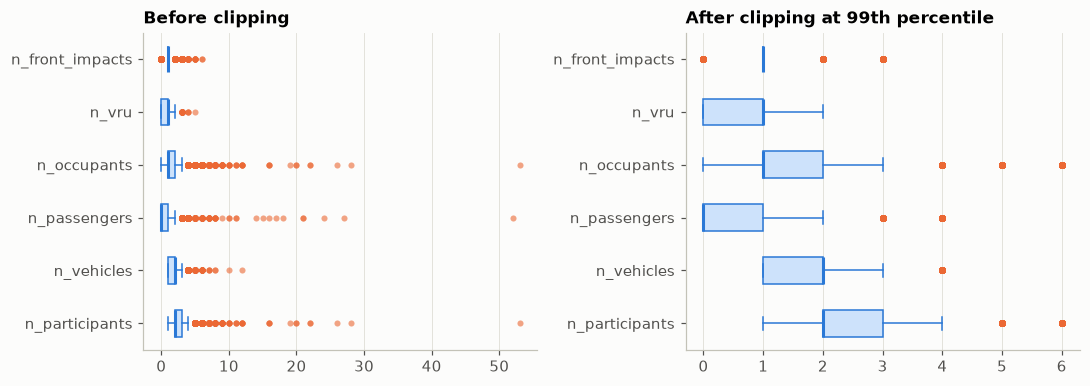

In [17]:
clip_cols = ["n_participants", "n_vehicles", "n_passengers", "n_occupants", "n_vru", "n_front_impacts"]
before = df[clip_cols].copy()                       # copy for the "before" boxplot
for col in clip_cols:
    cap = df.loc[train_mask, col].quantile(0.99)    # 99th percentile of training years
    df[col] = df[col].clip(upper=cap)
    print(f"{col}: clipped at {cap:.0f} ({(before[col] > cap).sum()} values)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, data, title in [(axes[0], before, "Before clipping"), (axes[1], df[clip_cols], "After clipping at 99th percentile")]:
    ax.boxplot([data[c].dropna() for c in clip_cols], vert=False, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
               whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
               flierprops=dict(marker="o", markersize=4, markerfacecolor=ORANGE, markeredgecolor="none", alpha=0.6))
    ax.set_yticks(range(1, len(clip_cols) + 1), clip_cols)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [18]:
# distance from the median location of the municipality (approx km)
mun_center = df[train_mask].groupby("municipality")[["lat", "lon"]].median()
center = mun_center.reindex(df["municipality"]).set_axis(df.index)
dist_km = np.hypot((df["lat"] - center["lat"]) * 111.2, (df["lon"] - center["lon"]) * 111.2 * np.cos(np.radians(55.2)))
far = dist_km > 50                                   # no municipality is that big
print(f"Accidents > 50 km from their municipality: {far.sum()}")
display(df.loc[far, ["municipality", "lat", "lon"]].assign(km_from_municipality=dist_km[far].round(0))
          .sort_values("km_from_municipality", ascending=False).head(8))
df.loc[far, ["lat", "lon"]] = np.nan

Accidents > 50 km from their municipality: 42


,municipality,lat,lon,km_from_municipality
registrokodas,,,,
07-25-9649313,Molėtų rajono sav.,54.098450,20.941811,311.0
07-23-9595664,Trakų rajono sav.,55.710484,21.469571,252.0
07-24-9629951,Mažeikių rajono sav.,54.256637,22.211568,228.0
07-22-9570072,Šiaulių miesto sav.,54.118634,23.160035,201.0
07-22-9580587,Kauno miesto sav.,55.510109,26.834851,196.0
07-23-9603476,Mažeikių rajono sav.,54.652164,22.365957,184.0
07-22-9570054,Kaišiadorių rajono sav.,56.345945,23.190584,181.0
07-22-9572134,Šiaulių rajono sav.,54.410592,23.870370,178.0


## 5.12 Missing values

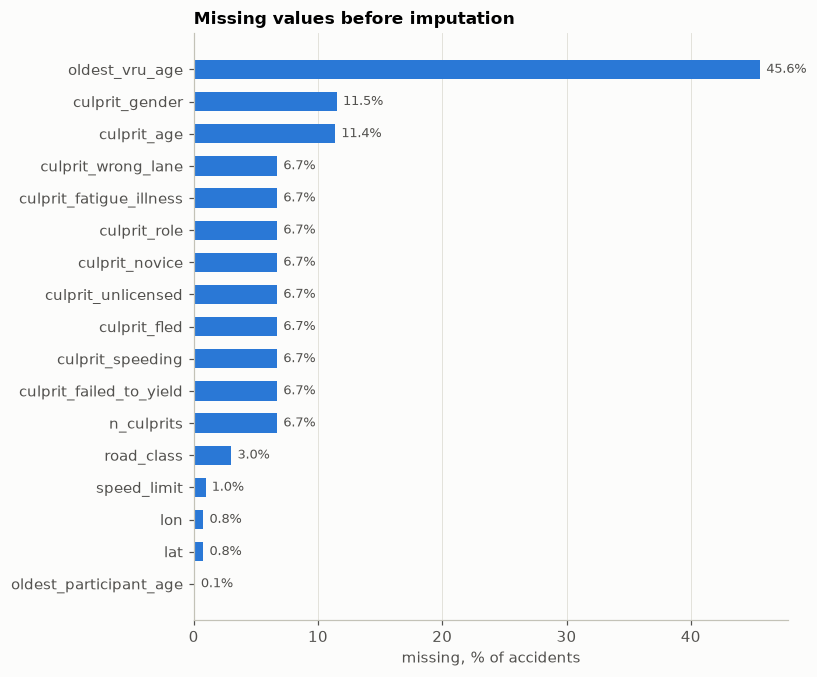

In [19]:
# % of missing values per column
missing = df.drop(columns=["split"]).isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(7.5, 0.32 * len(missing) + 0.8))
ax.barh(missing.index[::-1], missing.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(missing.values[::-1]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8.5, color=INK2)
ax.set_xlabel("missing, % of accidents")
ax.set_title("Missing values before imputation")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

How I fill missing values depends on why they are missing:

| Variable | Why missing | What I do |
|---|---|---|
| `oldest_vru_age` | no vulnerable road user in the accident, or the age is unknown | 0 if there is no VRU (together with `n_vru = 0`), otherwise the median VRU age of the training years |
| culprit features (`culprit_*`, `n_culprits`) | no culprit found (about 7 %) | category "Unknown", flags = False, `n_culprits` = 0 |
| `culprit_age` | no culprit or age unknown / invalid | training median + indicator column `culprit_age_missing` |
| `culprit_gender` | no culprit or not recorded | "Unknown" |
| vehicle features (`has_*_vehicle`, `has_truck`, `has_bus`, impacts) | no vehicle recorded | False / 0 |
| `oldest_participant_age` | all ages unknown | training median |
| `speed_limit` | invalid values removed in 5.9 | median of the same road class (training years) |
| `lat`, `lon` | placeholder, outside Lithuania (5.9) or misplaced (5.11) | median of the same municipality (training years) |
| `road_class` | no road name and no street name | "Unknown" |

In [20]:
# categories: new category "Unknown" (no culprit can also be useful information)
cat_unknown = ["culprit_role", "culprit_gender", "road_class"]
df[cat_unknown] = df[cat_unknown].fillna("Unknown")

# yes/no flags: missing = not present
flag_cols = ["culprit_novice", "culprit_unlicensed", "culprit_fled", "culprit_speeding", "culprit_failed_to_yield",
             "culprit_wrong_lane", "culprit_fatigue_illness", "has_heavy_vehicle", "has_truck", "has_bus",
             "has_foreign_vehicle", "any_side_impact", "any_rear_impact",
             "has_pedestrian", "has_cyclist", "has_powered_two_wheeler", "has_escooter", "has_child", "has_senior",
             "any_unbelted", "any_no_helmet", "vru_intoxicated"]
for col in flag_cols:
    df[col] = df[col].astype("boolean").fillna(False).astype(bool)
count_cols = ["n_culprits", "n_passengers", "n_occupants", "n_vru", "n_intoxicated", "n_front_impacts"]
df[count_cols] = df[count_cols].fillna(0)

# ages: first the indicator column, then the median
df["culprit_age_missing"] = df["culprit_age"].isna()
df["culprit_age"] = df["culprit_age"].fillna(df.loc[train_mask, "culprit_age"].median())
df["oldest_participant_age"] = df["oldest_participant_age"].fillna(df.loc[train_mask, "oldest_participant_age"].median())
no_vru = df["n_vru"].eq(0)
df.loc[no_vru, "oldest_vru_age"] = 0                                     # no VRU in the accident
vru_median = df.loc[train_mask & ~no_vru, "oldest_vru_age"].median()
df["oldest_vru_age"] = df["oldest_vru_age"].fillna(vru_median)          # VRU present but age unknown

# speed limit: median of the same road class (main road 90, city street 50)
speed_median = df[train_mask].groupby("road_class")["speed_limit"].median()
df["speed_limit"] = df["speed_limit"].fillna(df["road_class"].map(speed_median))
print("Speed-limit medians by road class (train):", speed_median.to_dict())

# coordinates: median of the same municipality (else overall median)
for col in ["lat", "lon"]:
    med = df[train_mask].groupby("municipality")[col].median()
    df[col] = df[col].fillna(df["municipality"].map(med)).fillna(df.loc[train_mask, col].median())

# True/False -> 1/0
bool_cols = df.select_dtypes(include="bool").columns
df[bool_cols] = df[bool_cols].astype(int)

print("Remaining missing values:", int(df.drop(columns=["split"]).isna().sum().sum()))

Speed-limit medians by road class (train): {'Local road': 50.0, 'Main road': 90.0, 'National road': 90.0, 'Regional road': 70.0, 'Street (settlement)': 50.0, 'Unknown': 70.0}
Remaining missing values: 0


## 5.13 Rare categories

Categories with less than 1 % of the training accidents are merged into "Other", because there are too few examples to learn from. `municipality` keeps all 60 values, because the Transformer in chapter 10 learns an embedding for each of them.

In [21]:
cat_cols = ["accident_type", "collision_scheme", "county", "municipality_type", "road_class", "junction",
            "surface_type", "surface_condition", "weather", "light_condition", "road_geometry",
            "culprit_role", "culprit_gender"]
for col in cat_cols:
    freq = df.loc[train_mask, col].value_counts(normalize=True)    # share of each category in training years
    rare = freq[freq < 0.01].index.tolist()
    if rare:
        df[col] = df[col].where(~df[col].isin(rare), "Other")
        print(f"{col}: merged {rare} -> 'Other'")

accident_type: merged ['Rail vehicle collision'] -> 'Other'
surface_condition: merged ['Contaminated'] -> 'Other'
light_condition: merged ['Dark, street lights off'] -> 'Other'
culprit_role: merged ['Passenger', 'Other'] -> 'Other'


## 5.14 Final dataset

In [22]:
NUM_FEATURES = ["hour", "month", "weekday", "speed_limit", "n_participants", "n_vehicles", "n_passengers",
                "n_occupants", "n_vru", "n_intoxicated", "n_front_impacts", "n_culprits", "culprit_age",
                "oldest_participant_age", "oldest_vru_age", "lat", "lon"]
BIN_FEATURES = ["is_weekend", "ped_crossing", "guardrail", "road_deficiency", "culprit_intoxicated",
                "has_pedestrian", "has_cyclist", "has_powered_two_wheeler", "has_escooter", "has_child", "has_senior",
                "any_unbelted", "any_no_helmet", "vru_intoxicated", "culprit_novice", "culprit_unlicensed", "culprit_fled",
                "culprit_speeding", "culprit_failed_to_yield", "culprit_wrong_lane", "culprit_fatigue_illness",
                "culprit_age_missing", "has_heavy_vehicle", "has_truck", "has_bus", "has_foreign_vehicle",
                "any_side_impact", "any_rear_impact"]
CAT_FEATURES = cat_cols + ["municipality"]
TARGET = "severe"

clean = df.reset_index().rename(columns={"registrokodas": "accident_id"})
clean = clean[["accident_id", "datetime", "year", "split"] + NUM_FEATURES + BIN_FEATURES + CAT_FEATURES + [TARGET]]
assert clean.isna().sum().sum() == 0 and clean["accident_id"].is_unique     # check: no NaN and unique ids

clean.to_csv(OUT_DIR / "accidents_clean.csv", index=False)
print(f"Saved {OUT_DIR / 'accidents_clean.csv'}: {clean.shape[0]} accidents x {clean.shape[1]} columns")
print(f"Features: {len(NUM_FEATURES)} numerical + {len(BIN_FEATURES)} binary + {len(CAT_FEATURES)} categorical "
      f"= {len(NUM_FEATURES) + len(BIN_FEATURES) + len(CAT_FEATURES)}")
clean.sample(5, random_state=RANDOM_STATE).T

Saved data/processed/accidents_clean.csv: 14049 accidents x 64 columns
Features: 17 numerical + 28 binary + 14 categorical = 59


,3289,7798,11243,4454,13016
accident_id,07-22-9570981,07-23-9606825,07-25-9634805,07-22-9579226,07-25-9645321
datetime,2022-04-04 23:07:00,2023-10-01 10:04:00,2025-01-01 23:17:00,2022-08-08 17:10:00,2025-08-24 14:15:00
year,2022,2023,2025,2022,2025
split,train,train,test,train,test
hour,23,10,23,17,14
...,...,...,...,...,...
road_geometry,"Straight, level",Curve,"Straight, level","Straight, level",Curve
culprit_role,Car driver,Other,Car driver,Car driver,Pedestrian
culprit_gender,Female,Male,Male,Male,Male
municipality,Klaipėdos rajono sav.,Panevėžio miesto sav.,Vilniaus miesto sav.,Vilniaus miesto sav.,Klaipėdos miesto sav.


In [23]:
# all features: type and range / share of 1 / number of categories
feature_table = pd.DataFrame(
    [(c, "numerical", f"{clean[c].min():g} … {clean[c].max():g}") for c in NUM_FEATURES]
    + [(c, "binary", f"{clean[c].mean():.1%} = 1") for c in BIN_FEATURES]
    + [(c, "categorical", f"{clean[c].nunique()} values") for c in CAT_FEATURES],
    columns=["feature", "type", "range / share / levels"])
feature_table

,feature,type,range / share / levels
0,hour,numerical,0 … 23
1,month,numerical,1 … 12
2,weekday,numerical,0 … 6
3,speed_limit,numerical,10 … 130
4,n_participants,numerical,1 … 6
5,n_vehicles,numerical,1 … 4
6,n_passengers,numerical,0 … 4
7,n_occupants,numerical,0 … 6
8,n_vru,numerical,0 … 2
9,n_intoxicated,numerical,0 … 6


# 6. Exploratory data analysis

All plots and statistics here use only the training years (2021-2024), so the test year stays unseen.

In [24]:
tr = clean[clean["split"] == "train"].copy()          # training years only
overall = tr[TARGET].mean()                           # overall severe share (line in the plots)
print(f"Training accidents: {len(tr)}, severe share: {overall:.1%}")

Training accidents: 11247, severe share: 29.7%


## 6.1 Target variable

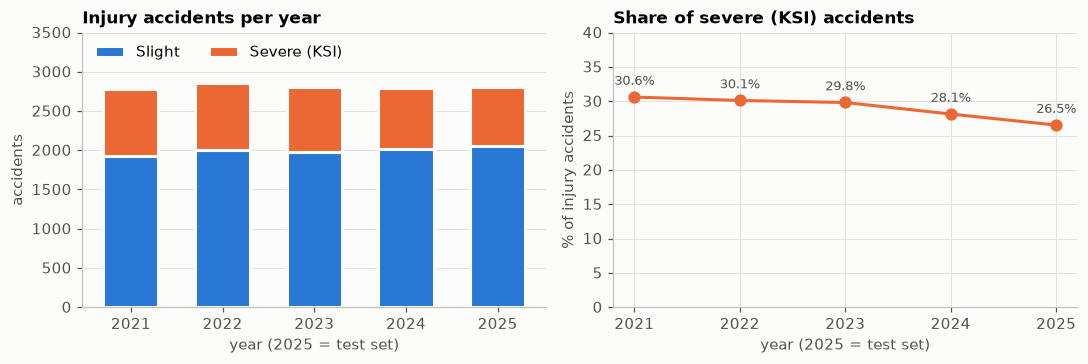

In [25]:
by_year = clean.groupby(["year", TARGET]).size().unstack()     # accidents per year and class
share = clean.groupby("year")[TARGET].mean()                   # severe share per year

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
ax.bar(by_year.index, by_year[0], color=CLASS_COLORS[0], width=0.6, label=CLASS_NAMES[0], edgecolor="#fcfcfb", linewidth=2)
ax.bar(by_year.index, by_year[1], bottom=by_year[0], color=CLASS_COLORS[1], width=0.6, label=CLASS_NAMES[1],
       edgecolor="#fcfcfb", linewidth=2)
ax.set_title("Injury accidents per year")
ax.set_ylabel("accidents")
ax.set_ylim(0, 3500)
ax.legend(loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.plot(share.index, share.values * 100, color=ORANGE, linewidth=2, marker="o", markersize=7)
for x, y in share.items():
    ax.annotate(f"{y:.1%}", (x, y * 100), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5, color=INK2)
ax.set_ylim(0, 40)
ax.set_title("Share of severe (KSI) accidents")
ax.set_ylabel("% of injury accidents")
ax.set_xticks(share.index)
for a in axes:
    a.set_xlabel("year (2025 = test set)")
plt.tight_layout()
plt.show()

## 6.2 Histograms of numerical features

The distributions of slight and severe accidents are drawn as densities, so they can be compared even though the groups have different sizes.

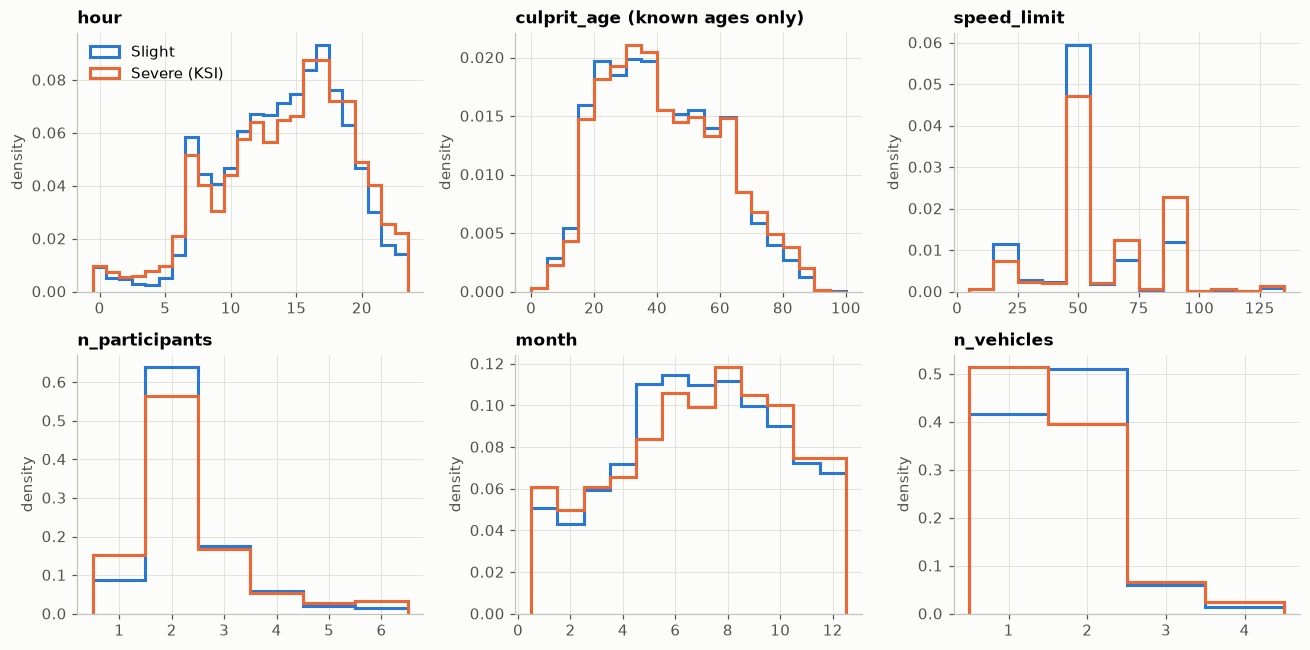

,count,mean,std,min,25%,50%,75%,max
hour,11247.0,14.03,4.78,0.00,11.00,15.00,18.00,23.00
month,11247.0,6.92,3.07,1.00,5.00,7.00,9.00,12.00
weekday,11247.0,2.90,1.92,0.00,1.00,3.00,4.00,6.00
speed_limit,11247.0,55.40,21.49,10.00,50.00,50.00,70.00,130.00
n_participants,11247.0,2.33,0.97,1.00,2.00,2.00,3.00,6.00
n_vehicles,11247.0,1.65,0.67,1.00,1.00,2.00,2.00,4.00
n_passengers,11247.0,0.47,0.85,0.00,0.00,0.00,1.00,4.00
n_occupants,11247.0,1.67,1.29,0.00,1.00,1.00,2.00,6.00
n_vru,11247.0,0.60,0.60,0.00,0.00,1.00,1.00,2.00
n_intoxicated,11247.0,0.13,0.40,0.00,0.00,0.00,0.00,6.00


In [26]:
hist_specs = [("hour", np.arange(-0.5, 24.5, 1)), ("culprit_age", np.arange(0, 101, 5)),
              ("speed_limit", np.arange(5, 141, 10)), ("n_participants", np.arange(0.5, 7.5, 1)),
              ("month", np.arange(0.5, 13.5, 1)), ("n_vehicles", np.arange(0.5, 5.5, 1))]
known_age = tr["culprit_age_missing"].eq(0)      # imputed ages would make a fake peak at the median
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (col, bins) in zip(axes.flat, hist_specs):
    data = tr[known_age] if col == "culprit_age" else tr
    for cls in [0, 1]:
        ax.hist(data.loc[data[TARGET] == cls, col], bins=bins, density=True, histtype="step", linewidth=2,
                color=CLASS_COLORS[cls], label=CLASS_NAMES[cls])
    ax.set_title(col + (" (known ages only)" if col == "culprit_age" else ""))
    ax.set_ylabel("density")
axes[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()

tr[NUM_FEATURES].describe().T.round(2)

## 6.3 Share of severe accidents by circumstance

Each bar is the share of severe accidents in that group, and the vertical line is the overall share. n is the number of training accidents in the group.

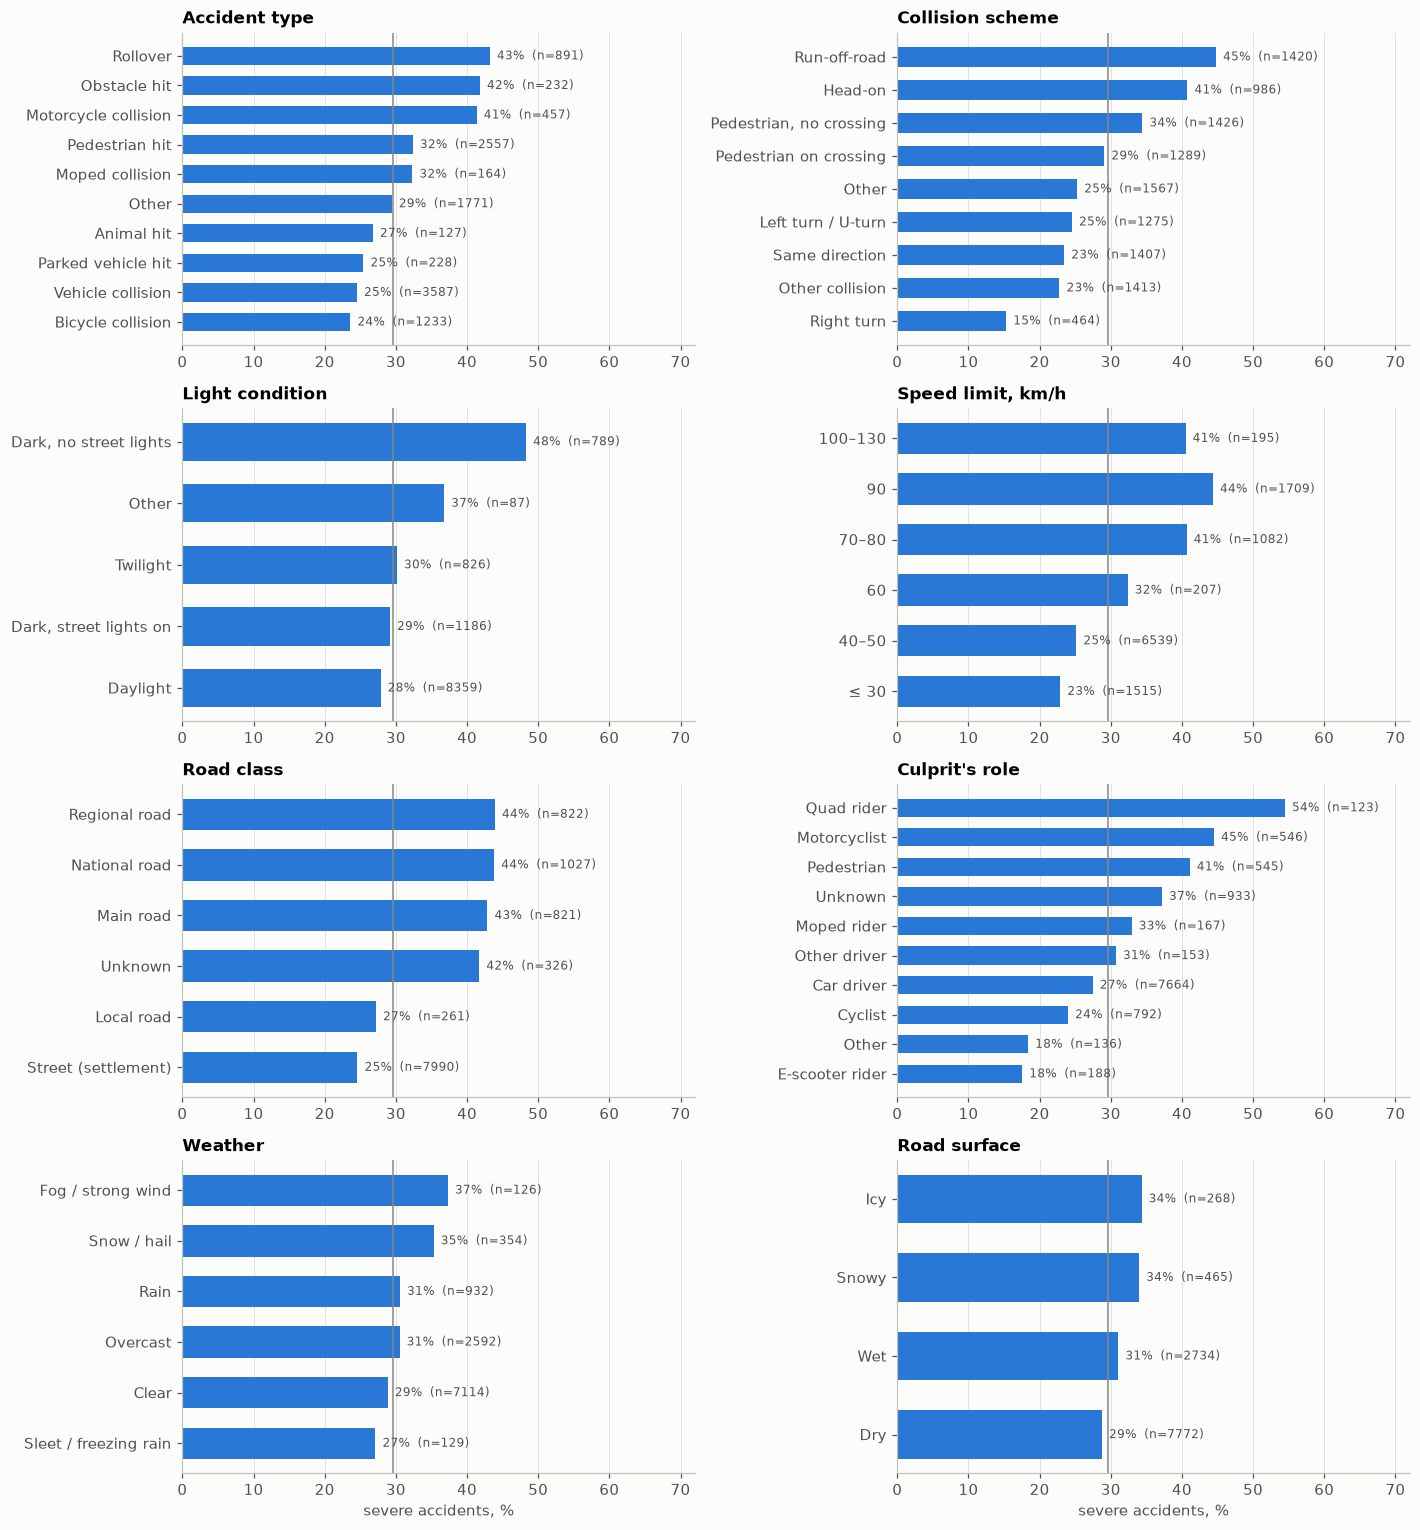

In [27]:
def severity_bars(ax, col, title, order=None, min_n=30):
    # severe share and size for every category of col (groups < 30 accidents are skipped)
    g = tr.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    g = g.loc[order] if order is not None else g.sort_values("mean")
    y = np.arange(len(g))
    ax.barh(y, g["mean"] * 100, color=BLUE, height=0.62)
    ax.axvline(overall * 100, color=MUTED, linewidth=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m * 100 + 1, i, f"{m:.0%}  (n={n})", va="center", fontsize=8, color=INK2)
    ax.set_yticks(y, [str(v) for v in g.index])
    ax.set_xlim(0, 72)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)


# helper columns only for plots and tests
tr["vulnerable_road_user"] = tr[["has_pedestrian", "has_cyclist", "has_powered_two_wheeler", "has_escooter"]].max(axis=1).map(
    {1: "Involved", 0: "Not involved"})
tr["speed_band"] = pd.cut(tr["speed_limit"], [0, 30, 50, 60, 80, 90, 130], labels=["≤ 30", "40–50", "60", "70–80", "90", "100–130"])

panels = [("accident_type", "Accident type", None), ("collision_scheme", "Collision scheme", None),
          ("light_condition", "Light condition", None), ("speed_band", "Speed limit, km/h", ["≤ 30", "40–50", "60", "70–80", "90", "100–130"]),
          ("road_class", "Road class", None), ("culprit_role", "Culprit's role", None),
          ("weather", "Weather", None), ("surface_condition", "Road surface", None)]
fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for ax, (col, title, order) in zip(axes.flat, panels):
    severity_bars(ax, col, title, order)
for ax in axes[-1]:
    ax.set_xlabel("severe accidents, %")
plt.tight_layout()
plt.show()

## 6.4 Scatter plots

(a, b) Maps: latitude / longitude of every training accident, slight and severe in separate plots.

(c) Municipalities: each dot is one of the 60 municipalities. x = share of its accidents on roads with speed limit >= 70 km/h, y = share of severe accidents, dot size = number of accidents.

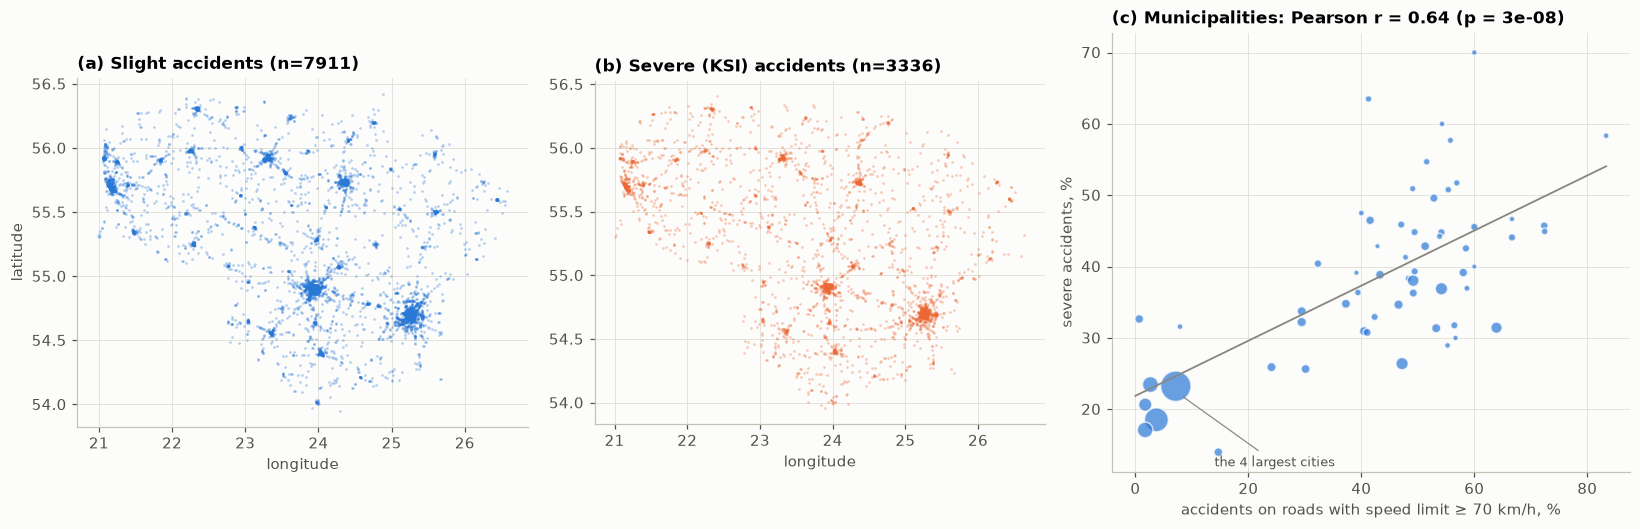

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.9), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for ax, cls in zip(axes[:2], [0, 1]):
    d = tr[tr[TARGET] == cls]
    ax.scatter(d["lon"], d["lat"], s=3, alpha=0.35, color=CLASS_COLORS[cls], linewidths=0)
    ax.set_aspect(1 / np.cos(np.radians(55.2)))      # keep the shape of lithuania on the map
    ax.set_xlabel("longitude")
    ax.set_title(f"({'ab'[cls]}) {CLASS_NAMES[cls]} accidents (n={len(d)})")
axes[0].set_ylabel("latitude")

# one point per municipality: % fast-road accidents vs % severe
mun = tr.groupby("municipality").agg(n=(TARGET, "size"), severe=(TARGET, "mean"),
                                     high_speed=("speed_limit", lambda s: (s >= 70).mean()))
r, p = stats.pearsonr(mun["high_speed"], mun["severe"])
ax = axes[2]
ax.scatter(mun["high_speed"] * 100, mun["severe"] * 100, s=mun["n"] / 6 + 8, color=BLUE, alpha=0.7,
           edgecolor="#fcfcfb", linewidth=1)
slope, intercept = np.polyfit(mun["high_speed"] * 100, mun["severe"] * 100, 1)   # trend line
xs = np.array([0, 100 * mun["high_speed"].max()])
ax.plot(xs, intercept + slope * xs, color=MUTED, linewidth=1.2)
ax.annotate("the 4 largest cities", xy=(8, 22), xytext=(14, 12), fontsize=8.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
ax.set_xlabel("accidents on roads with speed limit ≥ 70 km/h, %")
ax.set_ylabel("severe accidents, %")
ax.set_title(f"(c) Municipalities: Pearson r = {r:.2f} (p = {p:.0e})")
plt.tight_layout()
plt.show()

## 6.5 Correlation coefficients

For numerical and binary features I use the Pearson correlation (with a binary target this is the point-biserial correlation). For categorical features I use Cramér's V, which shows how strongly a category is connected to the target (0 = not at all, 1 = perfectly).

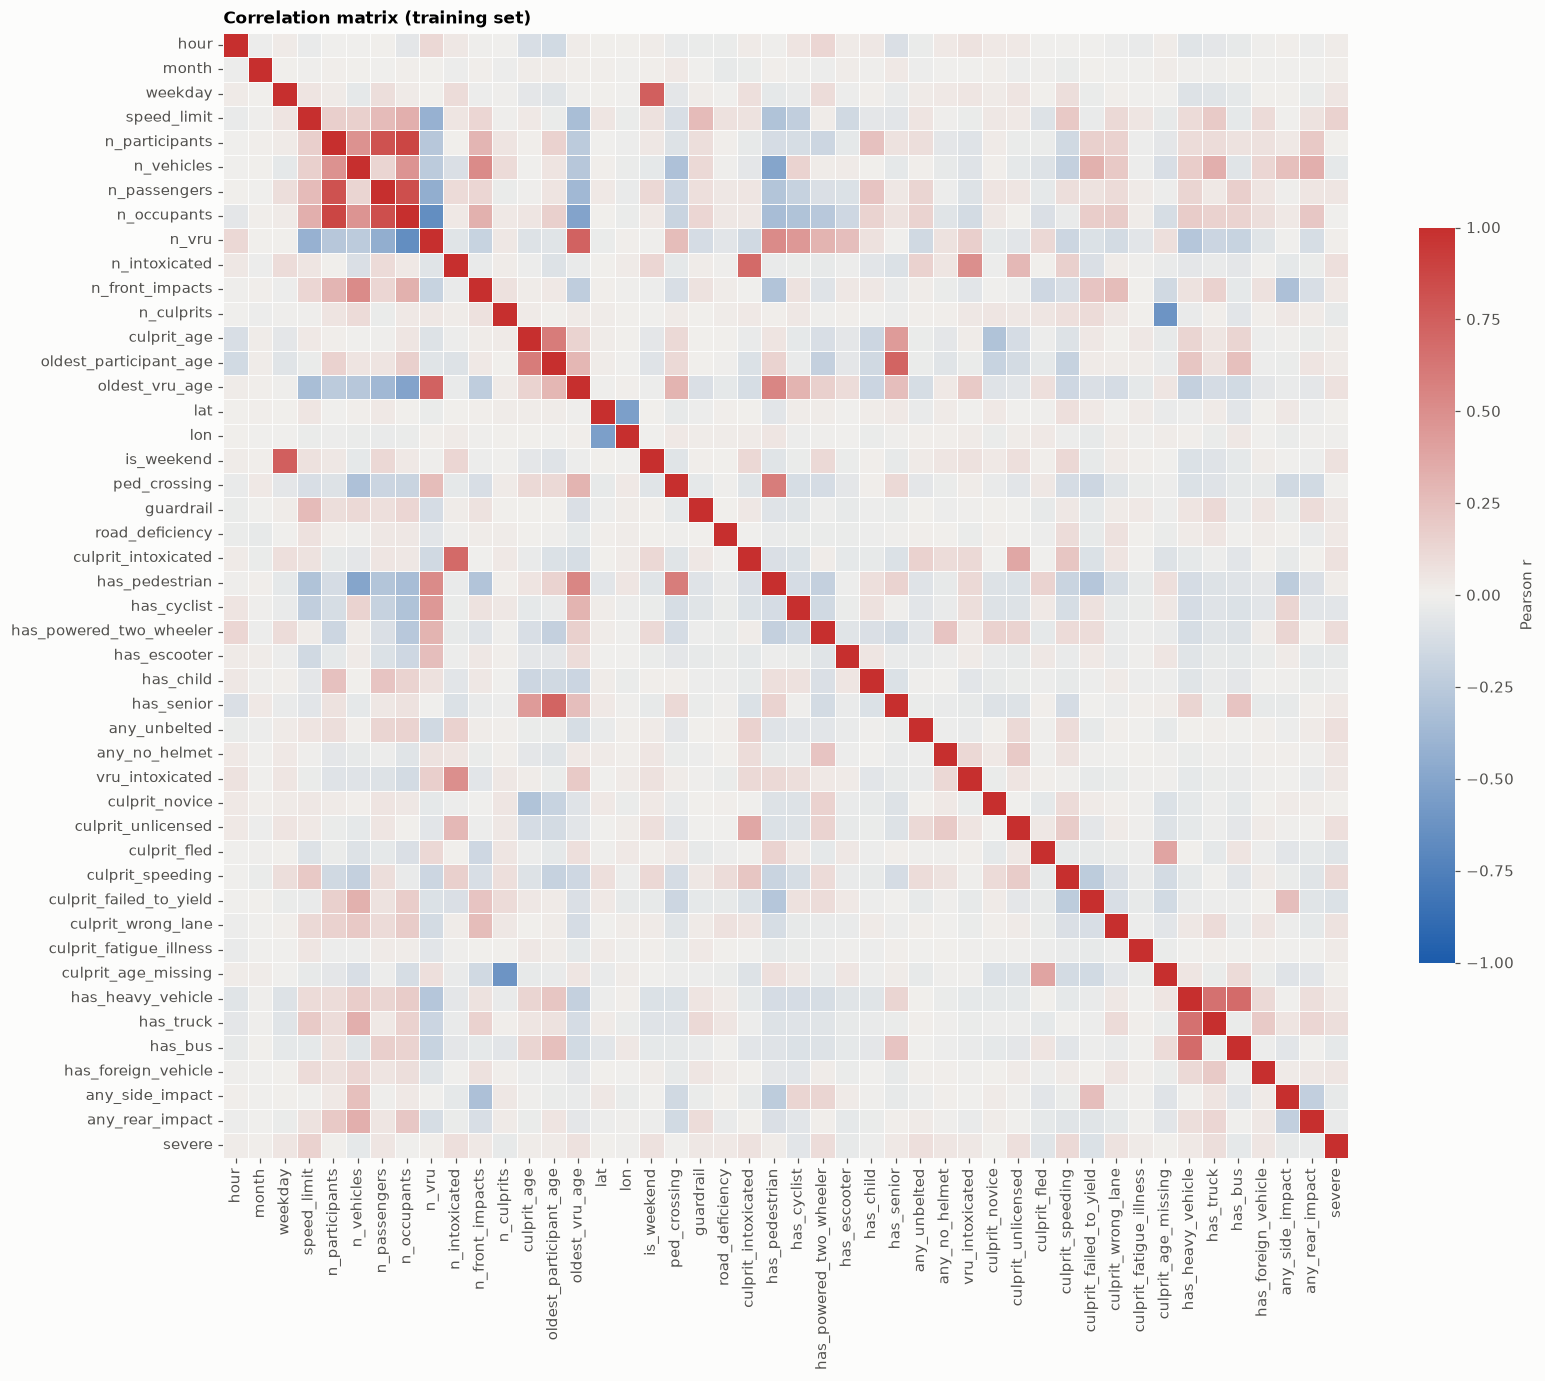

Strongest pairs between features (|r| > 0.5) — candidates for redundancy:


,level_0,level_1,r
176,n_participants,n_occupants,0.88
255,n_passengers,n_occupants,0.83
175,n_participants,n_passengers,0.82
103,weekday,is_weekend,0.75
337,n_vru,oldest_vru_age,0.73
520,oldest_participant_age,has_senior,0.72
380,n_intoxicated,culprit_intoxicated,0.69
1015,has_heavy_vehicle,has_bus,0.68
294,n_occupants,n_vru,-0.66
1014,has_heavy_vehicle,has_truck,0.65


In [29]:
corr_cols = NUM_FEATURES + BIN_FEATURES + [TARGET]
corr = tr[corr_cols].corr()                     # pearson correlation

fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, linecolor="#fcfcfb",
            cbar_kws={"shrink": 0.6, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix (training set)")
plt.tight_layout()
plt.show()

# pairs of features that are strongly correlated (upper triangle)
strong = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("r")
          .reset_index().assign(abs_r=lambda d: d["r"].abs()).sort_values("abs_r", ascending=False))
print("Strongest pairs between features (|r| > 0.5) — candidates for redundancy:")
strong[(strong["abs_r"] > 0.5) & (strong["level_0"] != TARGET) & (strong["level_1"] != TARGET)].drop(columns="abs_r").round(2)

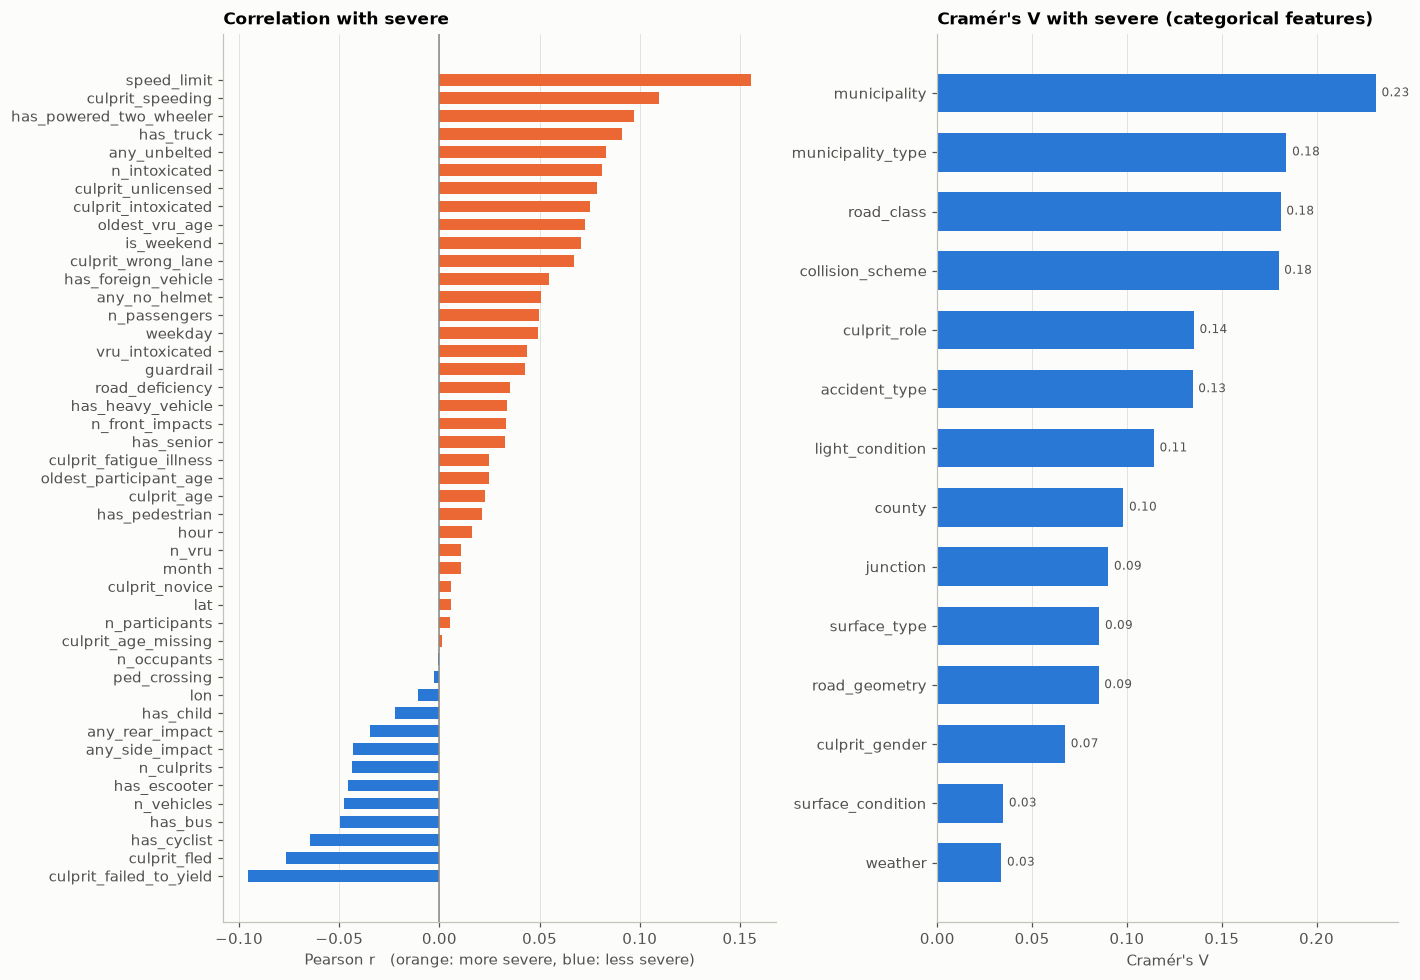

In [30]:
def cramers_v(x, y):
    # cramer's V = sqrt(chi2 / (n * (min(rows, cols) - 1))), between 0 and 1
    table = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


target_r = corr[TARGET].drop(TARGET).sort_values()
cv = pd.Series({c: cramers_v(tr[c], tr[TARGET]) for c in CAT_FEATURES}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 9), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ax.barh(target_r.index, target_r.values, color=[ORANGE if v > 0 else BLUE for v in target_r.values], height=0.65)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_title("Correlation with severe")
ax.set_xlabel("Pearson r   (orange: more severe, blue: less severe)")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(cv.index, cv.values, color=BLUE, height=0.65)
for i, v in enumerate(cv.values):
    ax.text(v + 0.003, i, f"{v:.2f}", va="center", fontsize=8, color=INK2)
ax.set_title("Cramér's V with severe (categorical features)")
ax.set_xlabel("Cramér's V")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 6.6 Statistical test of H1a-H1e

For each factor: share of severe accidents with and without it, the risk ratio, and a chi-square test of independence (H0: severity does not depend on the factor, alpha = 0.05).

In [31]:
tests = {
    "H1a  vulnerable road user involved": tr["vulnerable_road_user"].eq("Involved"),
    "H1b  speed limit ≥ 70 km/h": tr["speed_limit"].ge(70),
    "H1c  dark, no street lights": tr["light_condition"].eq("Dark, no street lights"),
    "H1d  culprit intoxicated": tr["culprit_intoxicated"].eq(1),
    "H1e  occupant without seat belt": tr["any_unbelted"].eq(1),
}
rows = []
for name, factor in tests.items():
    with_f, without_f = tr.loc[factor, TARGET].mean(), tr.loc[~factor, TARGET].mean()
    chi2, p = stats.chi2_contingency(pd.crosstab(factor, tr[TARGET]))[:2]       # 2x2 contingency table
    rows.append({"hypothesis": name, "accidents with factor": int(factor.sum()),
                 "severe % with": round(100 * with_f, 1), "severe % without": round(100 * without_f, 1),
                 "risk ratio": round(with_f / without_f, 2), "χ²": round(chi2, 1), "p-value": f"{p:.1e}",
                 "supported (p < 0.05, RR > 1)": "yes" if (p < 0.05 and with_f > without_f) else "no"})
pd.DataFrame(rows).set_index("hypothesis")

,accidents with factor,severe % with,severe % without,risk ratio,χ²,p-value,"supported (p < 0.05, RR > 1)"
hypothesis,,,,,,,
H1a vulnerable road user involved,6072,31.0,28.1,1.10,11.4,7.4e-04,yes
H1b speed limit ≥ 70 km/h,2986,42.8,24.9,1.72,333.8,1.4e-74,yes
"H1c dark, no street lights",789,48.3,28.3,1.71,140.2,2.4e-32,yes
H1d culprit intoxicated,681,43.2,28.8,1.50,62.7,2.4e-15,yes
H1e occupant without seat belt,712,44.2,28.7,1.54,76.7,2.0e-18,yes


## 6.7 EDA summary

After cleaning there are 14 049 injury accidents with 59 features (17 numerical, 28 binary, 14 categorical) and no missing values: 11 247 for training (2021-2024) and 2 802 for testing (2025).

Target: 29.7 % of training accidents are severe. The share goes down a little every year (30.6 % in 2021, 26.5 % in 2025), so the test year has fewer severe accidents. ROC-AUC does not depend on this, but the threshold has to be chosen carefully.

What makes an accident severe (training data):
* Speed and road type are the strongest signals. `speed_limit` has the highest correlation with the target (r = 0.16). The severe share is 23 % at 30 km/h or less and 41-44 % at 70 km/h or more, 25 % on city streets and 43-44 % on main, national and regional roads. Between the 60 municipalities, the share of accidents on fast roads is strongly correlated with the share of severe ones (r = 0.64, plot 6.4c). Big cities have many accidents, but mostly slight ones.
* Type of crash: run-off-road (45 %), rollover (43 %), head-on (41 %) and motorcycle collisions (41 %) are the most dangerous, right turn (15 %) and same direction (23 %) the least.
* Darkness without street lights: 48 % severe, compared to 28 % in daylight and 29 % in the dark with lights on. So the lighting itself matters, not only the time.
* Behaviour: speeding, intoxicated or unlicensed culprit, more intoxicated people and no seat belt make it more severe. Failure to yield (slow junction crashes in towns) and culprit fled (hit-and-run, usually minor) make it less severe.
* Heavy vehicles: a truck makes it more severe (r = +0.09), a bus less (r = -0.05). Bus accidents have many passengers who are usually only slightly hurt.
* Weather and road surface matter surprisingly little (Cramér's V = 0.03). Probably people drive slower in bad weather.
* Vulnerable road users are not one group: motorcyclists, quad riders and pedestrians have high risk, but cyclists (24 %) and e-scooter riders (18 %) are below average.

What this means for the models:
* Every single feature is only weakly connected to the target (|r| <= 0.16, Cramér's V <= 0.23). Severity comes from many small factors together, so it makes sense to try non-linear models that can combine them (H2).
* Some count features are strongly correlated (`n_participants`-`n_occupants` 0.88, `n_passengers`-`n_occupants` 0.83, `weekday`-`is_weekend` 0.75). I keep them: trees are not hurt by this and the neural networks use L2 regularisation.
* `municipality` has the highest Cramér's V (0.23) but 60 values, so in the Transformer it gets an embedding.

Supporting hypotheses (6.6): all five factors are significant (p < 0.001), so H1a-H1e are supported. The strongest are speed limit >= 70 km/h (risk ratio 1.72) and darkness without lights (1.71), then intoxicated culprit (1.50) and no seat belt (1.54). Vulnerable road users have only a weak effect (1.10), because this group mixes high-risk motorcyclists and pedestrians with lower-risk cyclists and e-scooter riders.

# 7. Preparing the data for the models

Here I prepare everything that all models share, so the comparison in chapter 11 is fair:

1. Model inputs - the same 59 features for every model, hour / month / weekday as sine and cosine.
2. Validation by year, the same way the models would be used in practice:

| Set | Years | Used for |
|---|---|---|
| fit | 2021-2023 | training while tuning hyperparameters |
| validation | 2024 | choosing hyperparameters, number of epochs and the threshold |
| train (final) | 2021-2024 | training the final model with the chosen parameters |
| test | 2025 | only once, for the final evaluation |

3. Metrics and the decision threshold.
4. Baselines: majority class and logistic regression.
5. Leakage check: what happens if outcome fields are used by mistake.

## 7.1 Model inputs

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline

model_df = clean.copy()
# hour, month and weekday are cyclic (23:00 is close to 00:00, december is close to january),
# sin and cos keep this, a plain number 0-23 would put 23 far from 0
for col, period in [("hour", 24), ("month", 12), ("weekday", 7)]:
    model_df[f"{col}_sin"] = np.sin(2 * np.pi * model_df[col] / period)
    model_df[f"{col}_cos"] = np.cos(2 * np.pi * model_df[col] / period)

CYCLIC = ["hour_sin", "hour_cos", "month_sin", "month_cos", "weekday_sin", "weekday_cos"]
NUM_MODEL = [c for c in NUM_FEATURES if c not in ("hour", "month", "weekday")] + CYCLIC
BIN_MODEL = BIN_FEATURES
CAT_MODEL = CAT_FEATURES
X_COLS = NUM_MODEL + BIN_MODEL + CAT_MODEL

# split by year (see table above)
fit_df = model_df[model_df["year"] <= 2023]
val_df = model_df[model_df["year"] == 2024]
train_df = model_df[model_df["year"] <= 2024]
test_df = model_df[model_df["year"] == TEST_YEAR]
y_fit, y_val = fit_df[TARGET].to_numpy(), val_df[TARGET].to_numpy()
y_train, y_test = train_df[TARGET].to_numpy(), test_df[TARGET].to_numpy()

display(pd.DataFrame({"set": ["fit 2021–2023", "validation 2024", "train 2021–2024", "test 2025"],
                      "accidents": [len(fit_df), len(val_df), len(train_df), len(test_df)],
                      "severe share": [y_fit.mean(), y_val.mean(), y_train.mean(), y_test.mean()]}).round(3))


def make_onehot_preprocessor():
    # for logistic regression, random forest and MLP:
    #   numbers -> standardised, binary -> as is, categories -> one-hot
    # sparse_threshold=0 gives a normal matrix that keras can use
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_MODEL),
        ("bin", "passthrough", BIN_MODEL),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_MODEL),
    ], sparse_threshold=0)


n_inputs = make_onehot_preprocessor().fit(fit_df[X_COLS]).transform(fit_df[X_COLS].head()).shape[1]
print(f"Features: {len(NUM_MODEL)} numerical + {len(BIN_MODEL)} binary + {len(CAT_MODEL)} categorical "
      f"-> {n_inputs} input columns after one-hot encoding")

,set,accidents,severe share
0,fit 2021–2023,8449,0.302
1,validation 2024,2798,0.281
2,train 2021–2024,11247,0.297
3,test 2025,2802,0.265


Features: 20 numerical + 28 binary + 14 categorical -> 187 input columns after one-hot encoding


## 7.2 Metrics and decision threshold

| Metric | What it means | Why I use it |
|---|---|---|
| ROC-AUC (main) | probability that the model gives a random severe accident a higher score than a random slight one; 0.5 = guessing | does not depend on the threshold or the class balance, so I use it for H1 and H2 |
| PR-AUC | area under the precision-recall curve; a random model gets the share of severe accidents (about 0.27) | focuses on the severe class |
| accuracy / error rate | share of correct / wrong predictions | required by the task, but misleading alone - always answering "slight" gives about 73 % accuracy |
| balanced accuracy | average recall of both classes | fair for imbalanced data (0.5 = guessing) |
| precision, recall, F1 (severe) | how many predicted severe are really severe, how many severe are found, and their harmonic mean | quality of the yes/no decision |

The models give a probability of a severe outcome. To get a yes/no answer I need a threshold. With 29 % severe accidents the usual 0.5 would almost never predict "severe", so for each model I choose the threshold with the best F1 of the severe class on the validation year 2024 and then use the same threshold on 2025.

In [33]:
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score, confusion_matrix, roc_curve)


def best_threshold(y_true, proba):
    # threshold with the best F1 of the severe class (on the validation year)
    thresholds = np.arange(0.05, 0.95, 0.01)
    f1s = [f1_score(y_true, (proba >= t).astype(int), zero_division=0) for t in thresholds]
    return float(thresholds[int(np.argmax(f1s))])


def evaluate(y_true, proba, threshold):
    # all metrics for one model on one data set
    pred = (proba >= threshold).astype(int)
    acc_value = accuracy_score(y_true, pred)
    return {"ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba),
            "accuracy": acc_value, "error rate": 1 - acc_value,
            "balanced accuracy": balanced_accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0)}


RESULTS = {}      # predictions of every model, used for the comparison in chapter 11


def store_results(name, p_train, p_test, threshold, p_val=None):
    # save predictions and return train / test metrics as a table
    RESULTS[name] = {"p_train": p_train, "p_test": p_test, "p_val": p_val, "threshold": threshold}
    table = pd.DataFrame([{"set": "train 2021–2024", **evaluate(y_train, p_train, threshold)},
                          {"set": "test 2025", **evaluate(y_test, p_test, threshold)}]).set_index("set")
    print(f"{name}: decision threshold = {threshold:.2f}")
    return table.round(3)


def fit_sklearn_and_store(name, make_pipeline):
    # 1) fit on 2021-2023 -> predict 2024 -> choose threshold
    # 2) fit again on 2021-2024 -> predict train and test
    p_val = make_pipeline().fit(fit_df[X_COLS], y_fit).predict_proba(val_df[X_COLS])[:, 1]
    threshold = best_threshold(y_val, p_val)
    final = make_pipeline().fit(train_df[X_COLS], y_train)
    table = store_results(name, final.predict_proba(train_df[X_COLS])[:, 1],
                          final.predict_proba(test_df[X_COLS])[:, 1], threshold, p_val)
    return final, table

## 7.3 Baselines

* Majority class - always predicts "slight". It shows why accuracy alone is misleading.
* Logistic regression - a simple linear model with balanced class weights. The models in chapters 8-10 should be better than this.

In [34]:
from sklearn.linear_model import LogisticRegression

# majority class: probability = share of severe in training, prediction = always "slight"
prior = y_train.mean()
table_majority = store_results("Majority class", np.full(len(y_train), prior), np.full(len(y_test), prior), threshold=0.5)
display(table_majority)

# logistic regression (baseline for all other models)
lr_model, table_lr = fit_sklearn_and_store(
    "Logistic regression",
    lambda: Pipeline([("prep", make_onehot_preprocessor()),
                      ("clf", LogisticRegression(max_iter=3000, C=0.2, class_weight="balanced"))]))
table_lr

Majority class: decision threshold = 0.50


,ROC-AUC,PR-AUC,accuracy,error rate,balanced accuracy,precision,recall,F1
set,,,,,,,,
train 2021–2024,0.5,0.297,0.703,0.297,0.5,0.0,0.0,0.0
test 2025,0.5,0.265,0.735,0.265,0.5,0.0,0.0,0.0


Logistic regression: decision threshold = 0.48


,ROC-AUC,PR-AUC,accuracy,error rate,balanced accuracy,precision,recall,F1
set,,,,,,,,
train 2021–2024,0.735,0.541,0.659,0.341,0.67,0.451,0.698,0.548
test 2025,0.727,0.504,0.661,0.339,0.67,0.416,0.690,0.519


## 7.4 Leakage check - why a much higher score would be suspicious

To show why I removed the outcome fields in 5.5, I train the same logistic regression again but with three leaking fields: number of injured people, whether a criminal case was opened and whether the airbags opened. All three are known only after the crash. I evaluate on the validation year, so the test year is not touched.

In [35]:
# leaking fields from the raw tables (NOT in the clean dataset)
leak = pd.DataFrame({
    "n_injured": acc["suzeistuSkaicius"],
    "criminal_case": part.assign(c=part["teisenosStadijaBusena"].eq("IKITEISMINIS")).groupby("registrokodas")["c"].max(),
    "airbag_deployed": part.assign(a=part["oroPagalves"].eq("Suveikė")).groupby("registrokodas")["a"].max(),
}).fillna(0).astype(int)
LEAK_COLS = list(leak.columns)

leak_fit = fit_df.join(leak, on="accident_id")
leak_val = val_df.join(leak, on="accident_id")
rows = []
for label, extra in [("honest features (this project)", []), ("+ 3 leaking outcome fields", LEAK_COLS)]:
    prep = ColumnTransformer([("num", StandardScaler(), NUM_MODEL + extra), ("bin", "passthrough", BIN_MODEL),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_MODEL)], sparse_threshold=0)
    pipe = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=3000, C=0.2, class_weight="balanced"))])
    pipe.fit(leak_fit[X_COLS + extra], y_fit)
    rows.append({"logistic regression with": label,
                 "validation ROC-AUC": roc_auc_score(y_val, pipe.predict_proba(leak_val[X_COLS + extra])[:, 1])})
pd.DataFrame(rows).round(3)

,logistic regression with,validation ROC-AUC
0,honest features (this project),0.702
1,+ 3 leaking outcome fields,0.785


With these three fields the validation ROC-AUC goes up from 0.702 to 0.785. The model is not better at predicting severity, it just reads the answer from the data (many injured people, criminal case, airbags). In real use this model is useless, because these fields don't exist yet when we need the prediction.

So for this task a ROC-AUC around 0.70-0.75 is a realistic result. A much higher score on the same data would most likely mean leakage (or a random train/test split that puts the same period in both sets).

# 8. Machine learning algorithm (except neural network) - Random forest

A random forest is a set of many decision trees. Each tree is trained on a random bootstrap sample of the accidents, and at every split it looks only at a random subset of features. The forest then averages the votes of all trees. Because of the averaging it overfits less than one deep tree, and trees can naturally find non-linear effects and combinations of features (for example pedestrian and dark and 90 km/h).

Parameters I analyse (first one at a time, then grid search):

| Parameter | Meaning |
|---|---|
| `n_estimators` | number of trees - more trees give more stable results but are slower |
| `max_depth` | maximum depth of a tree - deep trees can memorise the training data |
| `min_samples_leaf` | minimum number of accidents in a leaf - bigger means smoother and less overfitting |
| `max_features` | share of features one split can look at - smaller means more different trees |
| `class_weight` | gives severe accidents more weight in training |
| `criterion` | how the quality of a split is measured (Gini or entropy) |

## 8.1 First model with default parameters

In [36]:
from sklearn.ensemble import RandomForestClassifier

# preprocessing fitted once on fit years, matrices reused below
rf_prep = make_onehot_preprocessor().fit(fit_df[X_COLS])
Xf_rf, Xv_rf = rf_prep.transform(fit_df[X_COLS]), rf_prep.transform(val_df[X_COLS])


def rf_scores(**params):
    # train a forest on 2021-2023, return AUC on train and on 2024
    model = RandomForestClassifier(**{"n_estimators": 300, "n_jobs": -1, "random_state": RANDOM_STATE, **params})
    model.fit(Xf_rf, y_fit)
    return (roc_auc_score(y_fit, model.predict_proba(Xf_rf)[:, 1]),
            roc_auc_score(y_val, model.predict_proba(Xv_rf)[:, 1]))


train_auc, val_auc = rf_scores()
print(f"Default random forest (300 trees, unlimited depth): train ROC-AUC = {train_auc:.3f}, validation ROC-AUC = {val_auc:.3f}")

Default random forest (300 trees, unlimited depth): train ROC-AUC = 1.000, validation ROC-AUC = 0.696


With default parameters every tree grows until the leaves are pure, so the forest memorises the training accidents (train ROC-AUC about 1.0) but is much weaker on the next year. This is clear overfitting. In the parameter analysis I look for settings that work better on new data.

## 8.2 Parameter analysis (one parameter at a time)

I start from the default model and change one parameter at a time. The forest is trained on 2021-2023 and evaluated on 2021-2023 (train) and 2024 (validation). The gap between the two lines shows the overfitting.

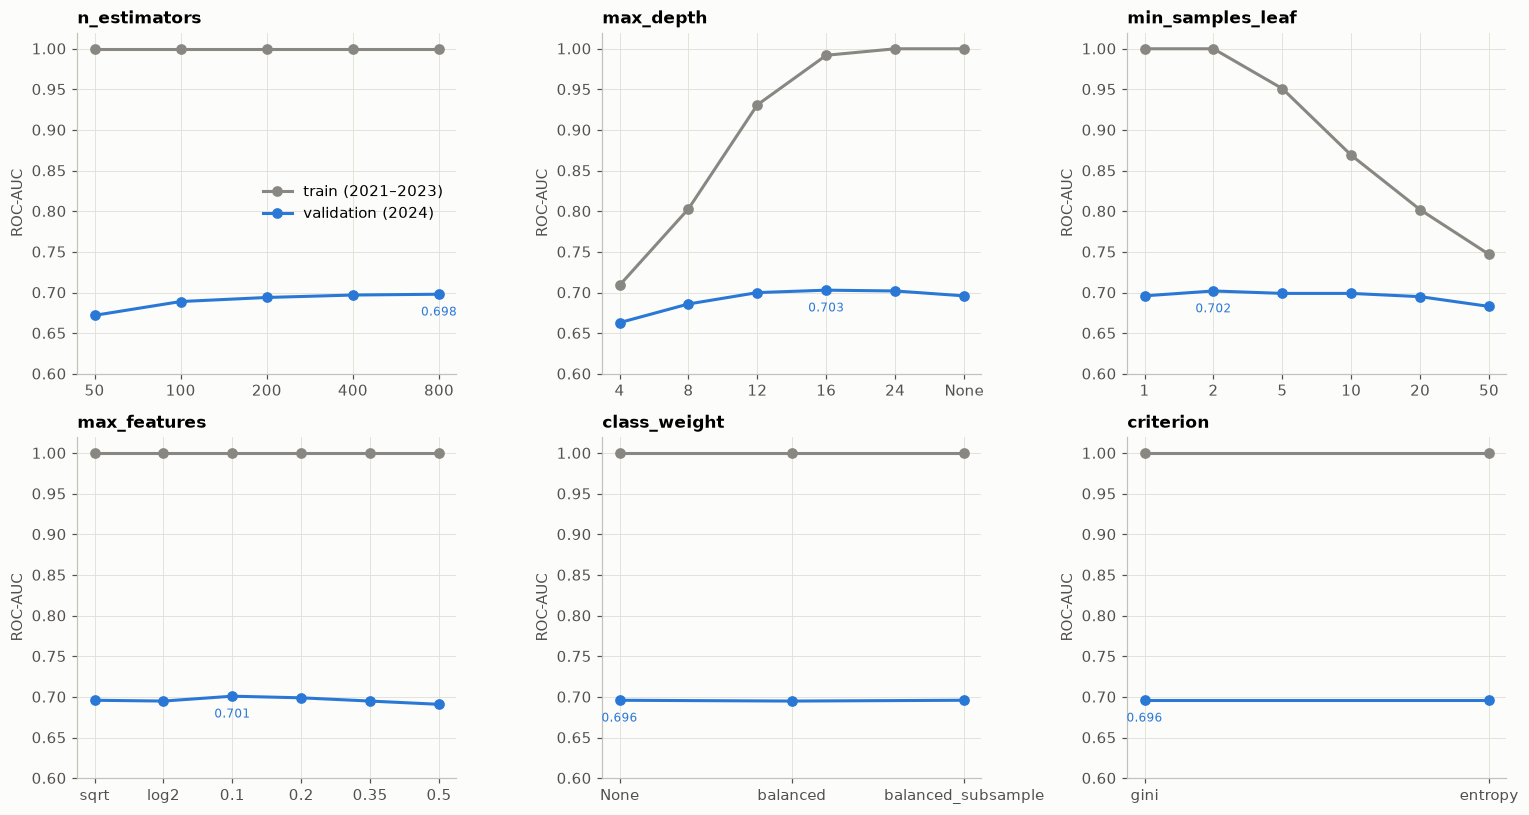

train ROC-AUC  validation ROC-AUC
parameter        value                                                
n_estimators     50                          1.000               0.672
                 100                         1.000               0.689
                 200                         1.000               0.694
                 400                         1.000               0.697
                 800                         1.000               0.698
max_depth        4                           0.709               0.663
                 8                           0.803               0.686
                 12                          0.931               0.700
                 16                          0.992               0.703
                 24                          1.000               0.702
                 None                        1.000               0.696
min_samples_leaf 1                           1.000               0.696
                 2                           1.000               0.702
                 5                           0.951               0.699
                 10                          0.869               0.699
                 20                          0.802               0.695
                 50                          0.747               0.683
max_features     sqrt                        1.000               0.696
                 log2                        1.000               0.695
                 0.1                         1.000               0.701
                 0.2                         1.000               0.699
                 0.35                        1.000               0.695
                 0.5                         1.000               0.691
class_weight     None                        1.000               0.696
                 balanced                    1.000               0.695
                 balanced_subsample          1.000               0.696
criterion        gini                        1.000               0.696
                 entropy                     1.000               0.696

In [37]:
RF_GRID_1D = {
    "n_estimators": [50, 100, 200, 400, 800],
    "max_depth": [4, 8, 12, 16, 24, None],
    "min_samples_leaf": [1, 2, 5, 10, 20, 50],
    "max_features": ["sqrt", "log2", 0.1, 0.2, 0.35, 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
    "criterion": ["gini", "entropy"],
}
rf_rows = []
for param, values in RF_GRID_1D.items():
    for value in values:
        train_auc, val_auc = rf_scores(**{param: value})
        rf_rows.append({"parameter": param, "value": str(value), "train ROC-AUC": train_auc, "validation ROC-AUC": val_auc})
rf_1d = pd.DataFrame(rf_rows)

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (param, group) in zip(axes.flat, rf_1d.groupby("parameter", sort=False)):
    x = np.arange(len(group))
    ax.plot(x, group["train ROC-AUC"], color=MUTED, linewidth=2, marker="o", markersize=6, label="train (2021–2023)")
    ax.plot(x, group["validation ROC-AUC"], color=BLUE, linewidth=2, marker="o", markersize=6, label="validation (2024)")
    best = group["validation ROC-AUC"].idxmax()
    ax.annotate(f"{group.loc[best, 'validation ROC-AUC']:.3f}", (x[list(group.index).index(best)], group.loc[best, "validation ROC-AUC"]),
                textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color=BLUE)
    ax.set_xticks(x, group["value"])
    ax.set_title(param)
    ax.set_ylim(0.6, 1.02)
    ax.set_ylabel("ROC-AUC")
axes[0, 0].legend(loc="center right")
plt.tight_layout()
plt.show()

rf_1d.pivot_table(index=["parameter", "value"], values=["train ROC-AUC", "validation ROC-AUC"], sort=False).round(3)

What the plots show:
* `max_depth` is the typical overfitting curve: train AUC goes up to 1.0, but validation is best at depth 16 (0.703) and a bit worse with unlimited trees (0.696). Depth 4 is too simple (0.663).
* `min_samples_leaf`: bigger leaves lower the train AUC from 1.0 to 0.75 (less memorising). Validation stays around 0.70 up to 10-20 accidents per leaf and drops at 50 (0.683, underfitting).
* `n_estimators`: more trees make the forest more stable (0.672 with 50 trees, 0.698 with 800). After about 400 trees there is almost no gain.
* `max_features`, `class_weight` and `criterion` change the validation AUC by less than 0.01. (Class weights change the probabilities but almost not the ranking of the accidents, so ROC-AUC stays the same.)
* In all settings the forest fits the training years much better than the next year. The useful information in the features is limited, and the extra flexibility is used to learn noise.

## 8.3 Grid search of the most important parameters together

Parameters influence each other, so I combine the most promising values in `GridSearchCV`. Instead of random folds I use `PredefinedSplit`: train on 2021-2023, validate on 2024, the same validation as for the neural networks. The preprocessing is inside the pipeline, so it is fitted only on the training part.

In [38]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit

rf_pipeline = Pipeline([("prep", make_onehot_preprocessor()),
                        ("rf", RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE))])
rf_param_grid = {
    "rf__max_depth": [12, 20, None],
    "rf__min_samples_leaf": [1, 3, 5, 10],
    "rf__max_features": ["sqrt", 0.2],
    "rf__class_weight": [None, "balanced_subsample"],
}
# test_fold = 0 for 2024 (validation), -1 = always training (2021-2023)
temporal_split = PredefinedSplit(test_fold=np.where(train_df["year"] == 2024, 0, -1))
rf_search = GridSearchCV(rf_pipeline, rf_param_grid, cv=temporal_split, scoring="roc_auc", refit=False, n_jobs=1)
rf_search.fit(train_df[X_COLS], y_train)

n_comb = len(rf_search.cv_results_["params"])
print(f"{n_comb} combinations tested; best validation ROC-AUC = {rf_search.best_score_:.3f}")
print("Best parameters:", rf_search.best_params_)
rf_grid_table = (pd.DataFrame(rf_search.cv_results_)[["params", "mean_test_score"]]
                 .rename(columns={"mean_test_score": "validation ROC-AUC"})
                 .sort_values("validation ROC-AUC", ascending=False))
rf_grid_table.head(10).round(4)

48 combinations tested; best validation ROC-AUC = 0.704
Best parameters: {'rf__class_weight': None, 'rf__max_depth': 20, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 3}


,params,validation ROC-AUC
9,"{'rf__class_weight': None, 'rf__max_depth': 20...",0.7041
8,"{'rf__class_weight': None, 'rf__max_depth': 20...",0.7038
10,"{'rf__class_weight': None, 'rf__max_depth': 20...",0.7021
5,"{'rf__class_weight': None, 'rf__max_depth': 12...",0.7020
4,"{'rf__class_weight': None, 'rf__max_depth': 12...",0.7016
17,"{'rf__class_weight': None, 'rf__max_depth': No...",0.7014
6,"{'rf__class_weight': None, 'rf__max_depth': 12...",0.7008
23,"{'rf__class_weight': None, 'rf__max_depth': No...",0.7005
14,"{'rf__class_weight': None, 'rf__max_depth': 20...",0.7000
18,"{'rf__class_weight': None, 'rf__max_depth': No...",0.6998


## 8.4 Model with best parameters

The best combination is trained again on all training years (2021-2024) with 500 trees and evaluated once on the test year 2025.

In [39]:
RF_BEST = {k.replace("rf__", ""): v for k, v in rf_search.best_params_.items()}


def make_best_rf():
    return Pipeline([("prep", make_onehot_preprocessor()),
                     ("rf", RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE, **RF_BEST))])


rf_model, table_rf = fit_sklearn_and_store("Random forest", make_best_rf)
table_rf

Random forest: decision threshold = 0.31


,ROC-AUC,PR-AUC,accuracy,error rate,balanced accuracy,precision,recall,F1
set,,,,,,,,
train 2021–2024,0.974,0.952,0.891,0.109,0.904,0.756,0.936,0.836
test 2025,0.728,0.513,0.668,0.332,0.654,0.416,0.623,0.499


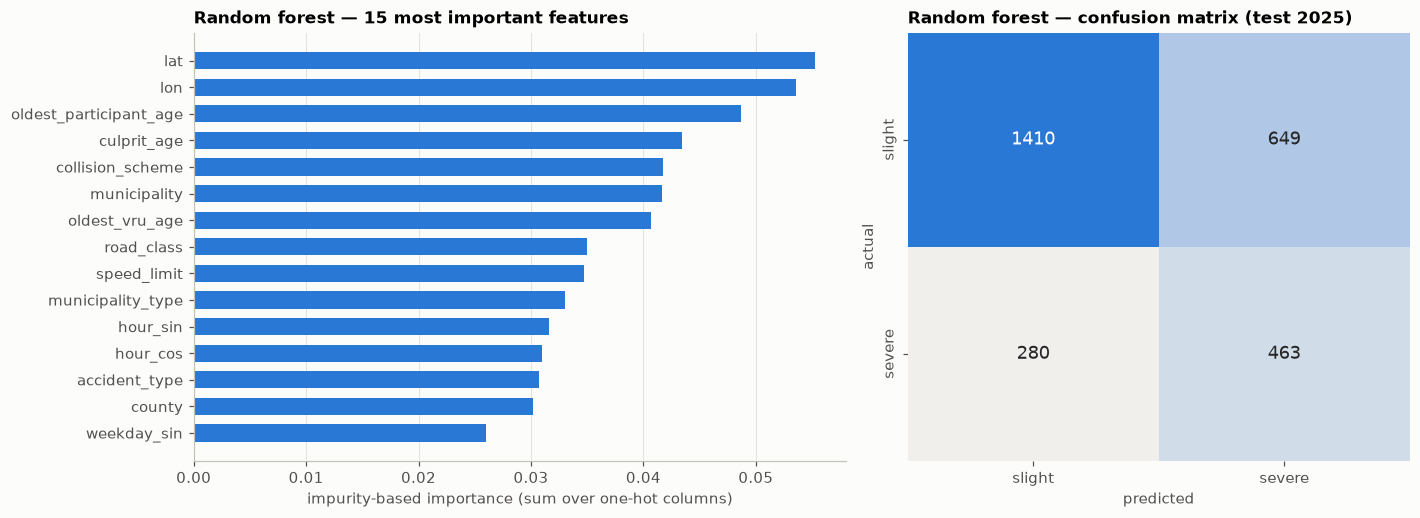

In [40]:
# which features does the forest use most? one-hot columns are summed back to the original feature
names = rf_model.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf_model.named_steps["rf"].feature_importances_, index=names)
original = [next(c for c in sorted(X_COLS, key=len, reverse=True) if n.split("__", 1)[1].startswith(c)) for n in names]
grouped = importances.groupby(original).sum().sort_values().tail(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.barh(grouped.index, grouped.values, color=BLUE, height=0.65)
ax.set_title("Random forest — 15 most important features")
ax.set_xlabel("impurity-based importance (sum over one-hot columns)")
ax.grid(axis="y", visible=False)

# confusion matrix on 2025
cm = confusion_matrix(y_test, (RESULTS["Random forest"]["p_test"] >= RESULTS["Random forest"]["threshold"]).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap=mcolors.LinearSegmentedColormap.from_list("b", ["#f0efec", BLUE]), cbar=False,
            xticklabels=["slight", "severe"], yticklabels=["slight", "severe"], ax=axes[1], annot_kws={"size": 12})
axes[1].set_xlabel("predicted")
axes[1].set_ylabel("actual")
axes[1].set_title("Random forest — confusion matrix (test 2025)")
plt.tight_layout()
plt.show()

Result: the grid search tested 48 combinations. The best one (max_depth = 20, min_samples_leaf = 3, max_features = sqrt, no class weights) gets 0.704 on the validation year. The ten best combinations are all between 0.700 and 0.704, so the optimum is quite flat.

On the test year 2025 the random forest has ROC-AUC = 0.728, almost the same as logistic regression (0.727). Its train AUC is 0.974, so the gap between train and test is 0.25 - even the tuned forest still memorises the training accidents. With threshold 0.31 it finds 62 % of the severe accidents (recall), and 42 % of its "severe" predictions are correct (precision). Accuracy is 66.8 % (error rate 33.2 %).

Note: impurity-based importance prefers numerical features with many possible split points (coordinates, ages), that's why `lat` / `lon` are at the top here. The permutation importance in 11.4 is a fairer measure.

# 9. 1st neural network - Multilayer perceptron (MLP)

Architecture: the MLP gets the same one-hot encoded input as the random forest (187 numbers per accident).

1. The input goes through one or more hidden layers of fully connected neurons, each layer calculates `activation(W*x + b)`.
2. Dropout randomly switches off some neurons during training, and an L2 penalty keeps the weights small. Both help against overfitting.
3. The output layer is one neuron with sigmoid activation, which gives the probability of a severe outcome.
4. Training minimises binary cross-entropy with the Adam optimizer.
5. Early stopping watches the validation ROC-AUC: if it does not improve for 8 epochs, training stops and the best weights are restored.

I analyse it in three steps:
1. a first network, to see how it learns;
2. changing one hyperparameter at a time;
3. a combined search with KerasTuner (Bayesian optimisation).

In [41]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"          # hide tensorflow start messages
import tensorflow as tf
import keras
from keras import layers
import keras_tuner as kt
tf.get_logger().setLevel("ERROR")                  # hide tensorflow retracing warnings

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| KerasTuner", kt.__version__)

# inputs for the network: preprocessing on fit years (tuning) and on all training years (final model)
mlp_prep_fit = make_onehot_preprocessor().fit(fit_df[X_COLS])
X_fit = mlp_prep_fit.transform(fit_df[X_COLS]).astype("float32")
X_val = mlp_prep_fit.transform(val_df[X_COLS]).astype("float32")
mlp_prep_full = make_onehot_preprocessor().fit(train_df[X_COLS])
X_train_full = mlp_prep_full.transform(train_df[X_COLS]).astype("float32")
X_test_full = mlp_prep_full.transform(test_df[X_COLS]).astype("float32")

# balanced class weights: a severe accident counts ~2.3x more in the loss
BALANCED = {0: 1.0, 1: float((y_fit == 0).sum() / (y_fit == 1).sum())}
OPTIMIZERS = {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop,
              "sgd": lambda learning_rate: keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)}


def build_mlp(n_inputs, hidden_layers=2, neurons=64, activation="relu", dropout=0.3, l2=1e-4,
              optimizer="adam", learning_rate=1e-3):
    model = keras.Sequential(name="MLP")
    model.add(keras.Input(shape=(n_inputs,)))
    for _ in range(hidden_layers):                                     # hidden layers, all the same size
        model.add(layers.Dense(neurons, activation=activation, kernel_regularizer=keras.regularizers.l2(l2)))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))                   # probability of a severe outcome
    model.compile(optimizer=OPTIMIZERS[optimizer](learning_rate=learning_rate), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc")])
    return model


def train_nn(model, x_tr, y_tr, x_va, y_va, batch_size=256, epochs=100, class_weight=None, patience=8):
    # training with early stopping on validation AUC, best weights are restored
    early_stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience, restore_best_weights=True)
    history = model.fit(x_tr, y_tr, validation_data=(x_va, y_va), epochs=epochs, batch_size=batch_size,
                        class_weight=class_weight, callbacks=[early_stop], verbose=0)
    best_epoch = int(np.argmax(history.history["val_auc"])) + 1
    return history, best_epoch


def predict(model, x):
    return model.predict(x, batch_size=2048, verbose=0).ravel()


build_mlp(X_fit.shape[1]).summary()

TensorFlow 2.21.0 | Keras 3.15.1 | KerasTuner 1.4.8


Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        12,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,257 (63.50 KB)

 Trainable params: 16,257 (63.50 KB)

 Non-trainable params: 0 (0.00 B)

## 9.1 First network and learning curves

The default network (2 hidden layers with 64 ReLU neurons, dropout 0.3, Adam) is first trained for 60 epochs without early stopping, to see how training and validation change over time.

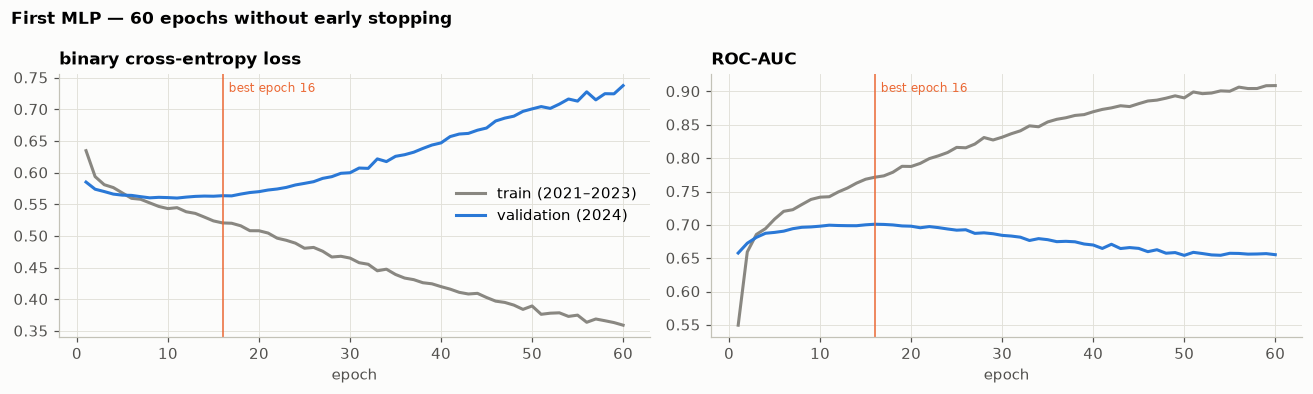

Best validation ROC-AUC 0.701 at epoch 16; after 60 epochs: train AUC 0.909, validation AUC 0.655


In [42]:
keras.utils.set_random_seed(RANDOM_STATE)
first_mlp = build_mlp(X_fit.shape[1])
first_history = first_mlp.fit(X_fit, y_fit, validation_data=(X_val, y_val), epochs=60, batch_size=256, verbose=0)


def plot_learning_curves(history, title, best_epoch=None):
    # loss and AUC per epoch for train and validation
    h = history.history
    epochs = np.arange(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    for ax, key, label in [(axes[0], "loss", "binary cross-entropy loss"), (axes[1], "auc", "ROC-AUC")]:
        ax.plot(epochs, h[key], color=MUTED, linewidth=2, label="train (2021–2023)")
        ax.plot(epochs, h[f"val_{key}"], color=BLUE, linewidth=2, label="validation (2024)")
        if best_epoch:
            ax.axvline(best_epoch, color=ORANGE, linewidth=1)
            ax.annotate(f"best epoch {best_epoch}", (best_epoch, ax.get_ylim()[1]), textcoords="offset points",
                        xytext=(4, -12), fontsize=8, color=ORANGE)
        ax.set_xlabel("epoch")
        ax.set_title(label)
    axes[0].legend()
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


best = int(np.argmax(first_history.history["val_auc"])) + 1
plot_learning_curves(first_history, "First MLP — 60 epochs without early stopping", best)
print(f"Best validation ROC-AUC {max(first_history.history['val_auc']):.3f} at epoch {best}; "
      f"after 60 epochs: train AUC {first_history.history['auc'][-1]:.3f}, validation AUC {first_history.history['val_auc'][-1]:.3f}")

Without early stopping the network overfits fast: the validation loss is lowest around epoch 10 and then grows, the validation ROC-AUC is best (0.701) in epoch 16, and after that the train AUC keeps going up to 0.909 while the validation AUC falls to 0.655. The network starts to memorise the training accidents. That's why all next experiments use early stopping together with dropout and L2.

## 9.2 Parameter analysis (one parameter at a time)

I change one hyperparameter at a time and keep the others at their default values. Each setting is trained 3 times with different random seeds (the result of a neural network depends on the random starting weights), with early stopping. The plots show the mean validation ROC-AUC (± standard deviation of the 3 seeds), and the table under them also has the train ROC-AUC and the number of epochs chosen by early stopping.

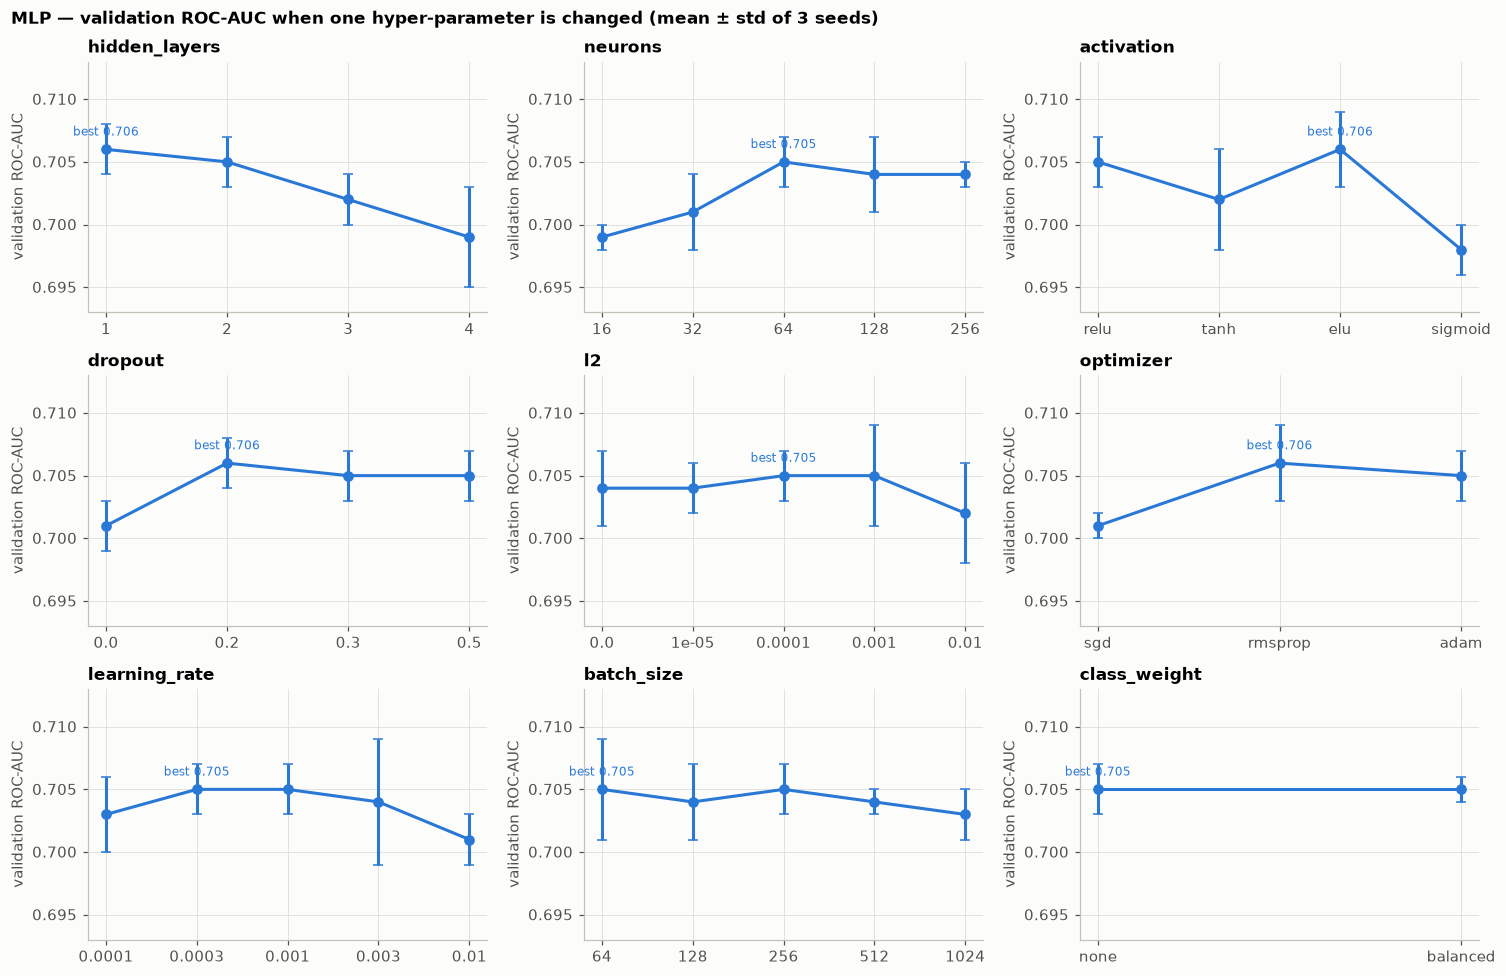

,parameter,value,train,validation,validation_std,epochs
0,hidden_layers,1,0.804,0.706,0.002,21.667
1,hidden_layers,2,0.788,0.705,0.002,13.667
2,hidden_layers,3,0.790,0.702,0.002,14.667
3,hidden_layers,4,0.797,0.699,0.004,14.667
4,neurons,16,0.777,0.699,0.001,29.000
5,neurons,32,0.780,0.701,0.003,19.333
6,neurons,64,0.788,0.705,0.002,13.667
7,neurons,128,0.797,0.704,0.003,9.333
8,neurons,256,0.797,0.704,0.001,6.000
9,activation,relu,0.788,0.705,0.002,13.667


In [43]:
MLP_DEFAULT = dict(hidden_layers=2, neurons=64, activation="relu", dropout=0.3, l2=1e-4, optimizer="adam", learning_rate=1e-3)
FIT_DEFAULT = dict(batch_size=256, class_weight=None)
MLP_GRID_1D = {
    "hidden_layers": [1, 2, 3, 4],
    "neurons": [16, 32, 64, 128, 256],
    "activation": ["relu", "tanh", "elu", "sigmoid"],
    "dropout": [0.0, 0.2, 0.3, 0.5],
    "l2": [0.0, 1e-5, 1e-4, 1e-3, 1e-2],
    "optimizer": ["sgd", "rmsprop", "adam"],
    "learning_rate": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
    "batch_size": [64, 128, 256, 512, 1024],
    "class_weight": ["none", "balanced"],
}
SEEDS = [1, 2, 3]
DEFAULT_LR = {"adam": 1e-3, "rmsprop": 1e-3, "sgd": 1e-2}     # each optimizer with its default learning rate


def run_mlp(model_params, fit_params, seed):
    keras.utils.set_random_seed(seed)
    model = build_mlp(X_fit.shape[1], **model_params)
    history, best_epoch = train_nn(model, X_fit, y_fit, X_val, y_val, **fit_params)
    return roc_auc_score(y_fit, predict(model, X_fit)), roc_auc_score(y_val, predict(model, X_val)), best_epoch


mlp_rows = []
for param, values in MLP_GRID_1D.items():
    for value in values:
        model_params, fit_params = dict(MLP_DEFAULT), dict(FIT_DEFAULT)
        if param == "batch_size":
            fit_params["batch_size"] = value
        elif param == "class_weight":
            fit_params["class_weight"] = BALANCED if value == "balanced" else None
        else:
            model_params[param] = value
            if param == "optimizer":
                model_params["learning_rate"] = DEFAULT_LR[value]
        for seed in SEEDS:
            tr_auc, va_auc, epochs_used = run_mlp(model_params, fit_params, seed)
            mlp_rows.append({"parameter": param, "value": str(value), "seed": seed, "train ROC-AUC": tr_auc,
                             "validation ROC-AUC": va_auc, "epochs": epochs_used})
mlp_1d = pd.DataFrame(mlp_rows)
mlp_1d_summary = mlp_1d.groupby(["parameter", "value"], sort=False).agg(
    train=("train ROC-AUC", "mean"), validation=("validation ROC-AUC", "mean"),
    validation_std=("validation ROC-AUC", "std"), epochs=("epochs", "mean")).reset_index()


def plot_1d(summary, ncols, title):
    # validation AUC for every value; the differences are small so the y axis is zoomed
    # (same range in every plot). train AUC and epochs are in the table
    std = summary["validation_std"].fillna(0) if "validation_std" in summary else 0 * summary["validation"]
    ylim = ((summary["validation"] - std).min() - 0.002, (summary["validation"] + std).max() + 0.004)
    groups = list(summary.groupby("parameter", sort=False))
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.0 * nrows))
    for ax, (param, g) in zip(axes.flat, groups):
        x = np.arange(len(g))
        yerr = g["validation_std"] if "validation_std" in g else None
        ax.errorbar(x, g["validation"], yerr=yerr, color=BLUE, linewidth=2, marker="o", markersize=6, capsize=3)
        i_best = int(np.argmax(g["validation"].to_numpy()))
        ax.annotate(f"best {g['validation'].iloc[i_best]:.3f}", (x[i_best], g["validation"].iloc[i_best]),
                    textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8, color=BLUE)
        ax.set_xticks(x, g["value"])
        ax.set_ylim(*ylim)
        ax.set_ylabel("validation ROC-AUC")
        ax.set_title(param)
    for ax in list(axes.flat)[len(groups):]:
        ax.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


plot_1d(mlp_1d_summary, 3, "MLP — validation ROC-AUC when one hyper-parameter is changed (mean ± std of 3 seeds)")
mlp_1d_summary.round(3)

What the plots show (all differences are small, the whole range is 0.698-0.706):
* Depth and width: 1-2 hidden layers are best (0.706 / 0.705), 4 layers are worse (0.699). 64-256 neurons are better than 16 (0.699). A bigger network doesn't help.
* Activation: ReLU and ELU are best (0.705 / 0.706). Sigmoid is the worst (0.698) and learns slowly (86 epochs on average) because it saturates.
* Regularisation: dropout 0.2-0.5 is better than no dropout (0.706 vs 0.701) and makes the train-validation gap smaller. L2 up to 0.001 is fine, 0.01 is too strong (train AUC drops to 0.757, underfitting).
* Optimizer and learning rate: SGD is the weakest (0.701, 60 epochs), Adam and RMSprop are better (0.705-0.706). Learning rate 0.0003-0.001 works best, 0.01 is too big (unstable, stops after 4 epochs), 0.0001 is too slow (98 epochs).
* Batch size has little effect between 64 and 512, 1024 is a bit worse.
* Class weights don't change the ROC-AUC (0.705 in both cases). They shift the probabilities but not the ranking of the accidents, so they matter for the threshold, not for the AUC.
* The standard deviation between seeds (about 0.002-0.004) is as big as most of the differences, so the parameters should be optimised together, which is the next step.

## 9.3 Combined search with KerasTuner (Bayesian optimisation)

The one-at-a-time analysis showed which ranges make sense. Because parameters influence each other, I search them together with KerasTuner Bayesian optimisation. The first trials are random, and later trials use the earlier results to suggest better combinations. Batch size and class weights are arguments of `fit()`, not of the model, so a small custom tuner passes them to training.

In [44]:
def build_mlp_hp(hp):
    # search space for keras tuner
    return build_mlp(
        X_fit.shape[1],
        hidden_layers=hp.Int("hidden_layers", 1, 3),
        neurons=hp.Choice("neurons", [16, 32, 64, 128]),
        activation=hp.Choice("activation", ["relu", "elu"]),
        dropout=hp.Float("dropout", 0.0, 0.5, step=0.1),
        l2=hp.Choice("l2", [0.0, 1e-5, 1e-4, 1e-3]),
        learning_rate=hp.Choice("learning_rate", [3e-4, 1e-3, 3e-3]))


class MLPTuner(kt.BayesianOptimization):
    # batch size and class weights go to fit(), not to the model, so pass them here
    def run_trial(self, trial, *args, **kwargs):
        hp = trial.hyperparameters
        kwargs["batch_size"] = hp.get("batch_size")
        kwargs["class_weight"] = BALANCED if hp.get("balanced_class_weight") else None
        return super().run_trial(trial, *args, **kwargs)


fit_hp = kt.HyperParameters()                      # register them before creating the tuner
fit_hp.Choice("batch_size", [128, 256, 512])
fit_hp.Boolean("balanced_class_weight")

mlp_tuner = MLPTuner(build_mlp_hp, objective=kt.Objective("val_auc", direction="max"), max_trials=30,
                     num_initial_points=8, hyperparameters=fit_hp, seed=RANDOM_STATE, overwrite=True,
                     directory="keras_tuner_results", project_name="mlp")
mlp_tuner.search(X_fit, y_fit, validation_data=(X_val, y_val), epochs=100, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8, restore_best_weights=True)])

# all trials as a table, best first
trials = [{**t.hyperparameters.values, "validation AUC": t.score} for t in mlp_tuner.oracle.trials.values() if t.score is not None]
mlp_trials = pd.DataFrame(trials).sort_values("validation AUC", ascending=False)
print(f"{len(mlp_trials)} trials finished")
mlp_trials.head(10).round(4)

30 trials finished


,batch_size,balanced_class_weight,hidden_layers,neurons,activation,dropout,l2,learning_rate,validation AUC
21,128,True,2,64,elu,0.1,0.0010,0.0010,0.7081
25,128,False,1,32,relu,0.3,0.0001,0.0010,0.7080
8,256,False,1,128,elu,0.2,0.0000,0.0003,0.7074
24,512,True,1,128,relu,0.4,0.0000,0.0003,0.7067
6,128,False,2,128,elu,0.3,0.0000,0.0003,0.7060
10,512,False,2,64,relu,0.3,0.0010,0.0030,0.7056
2,256,False,1,32,elu,0.2,0.0000,0.0010,0.7053
4,512,False,2,128,elu,0.0,0.0000,0.0010,0.7051
0,256,False,2,32,elu,0.1,0.0001,0.0003,0.7047
3,128,False,3,64,elu,0.1,0.0000,0.0003,0.7047


## 9.4 Model with best parameters

The best KerasTuner configuration is trained with 3 random seeds and the predictions of the 3 networks are averaged (this removes most of the randomness of one run):
1. trained on 2021-2023 with early stopping on 2024 -> learning curves, best number of epochs, validation predictions and threshold;
2. trained again on all training years 2021-2024 for the same number of epochs -> predictions for train and test.

Best hyper-parameters: {'batch_size': 128, 'balanced_class_weight': True, 'hidden_layers': 2, 'neurons': 64, 'activation': 'elu', 'dropout': 0.1, 'l2': 0.001, 'learning_rate': 0.001}


Epochs chosen by early stopping (3 seeds): [38, 22, 37]


Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 64)             │        12,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,773 (190.52 KB)

 Trainable params: 16,257 (63.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 32,516 (127.02 KB)

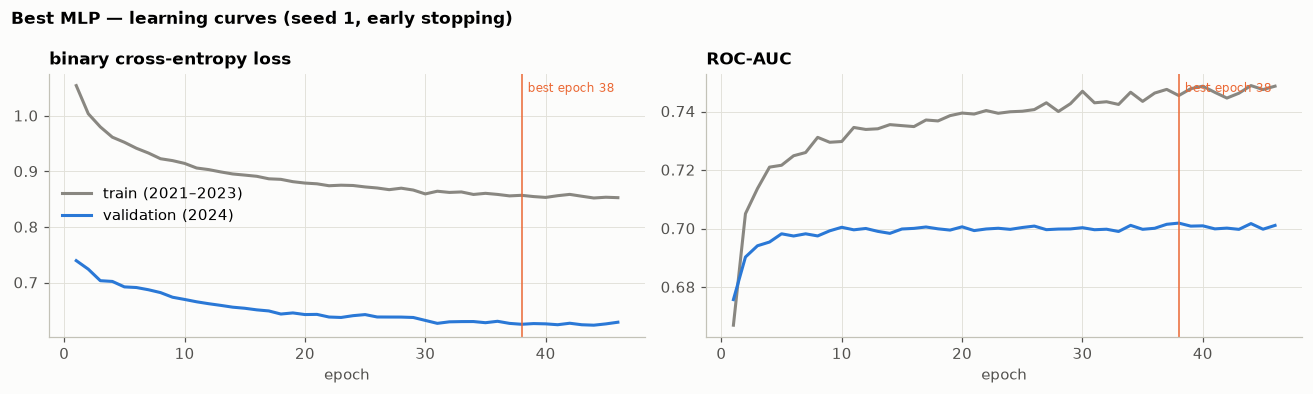

MLP: decision threshold = 0.47


,ROC-AUC,PR-AUC,accuracy,error rate,balanced accuracy,precision,recall,F1
set,,,,,,,,
train 2021–2024,0.753,0.572,0.671,0.329,0.685,0.465,0.717,0.564
test 2025,0.735,0.520,0.658,0.342,0.672,0.414,0.701,0.521


In [45]:
MLP_BEST_HP = mlp_tuner.get_best_hyperparameters(1)[0].values
print("Best hyper-parameters:", MLP_BEST_HP)
mlp_model_params = {k: MLP_BEST_HP[k] for k in ["hidden_layers", "neurons", "activation", "dropout", "l2", "learning_rate"]}
mlp_fit_params = {"batch_size": MLP_BEST_HP["batch_size"],
                  "class_weight": BALANCED if MLP_BEST_HP["balanced_class_weight"] else None}

p_val_list, p_train_list, p_test_list, mlp_epochs, final_mlps = [], [], [], [], []
for seed in SEEDS:
    # 1) fit years + early stopping on 2024
    keras.utils.set_random_seed(seed)
    model = build_mlp(X_fit.shape[1], **mlp_model_params)
    history, best_epoch = train_nn(model, X_fit, y_fit, X_val, y_val, **mlp_fit_params)
    p_val_list.append(predict(model, X_val))
    mlp_epochs.append(best_epoch)
    if seed == SEEDS[0]:
        best_mlp_history, best_mlp_epoch = history, best_epoch
    # 2) all training years, fixed number of epochs (no validation left for early stopping)
    keras.utils.set_random_seed(seed)
    final_mlp = build_mlp(X_train_full.shape[1], **mlp_model_params)
    final_mlp.fit(X_train_full, y_train, epochs=best_epoch, batch_size=mlp_fit_params["batch_size"],
                  class_weight=mlp_fit_params["class_weight"], verbose=0)
    p_train_list.append(predict(final_mlp, X_train_full))
    p_test_list.append(predict(final_mlp, X_test_full))
    final_mlps.append(final_mlp)

print("Epochs chosen by early stopping (3 seeds):", mlp_epochs)
final_mlp.summary()
plot_learning_curves(best_mlp_history, "Best MLP — learning curves (seed 1, early stopping)", best_mlp_epoch)

p_val_mlp = np.mean(p_val_list, axis=0)
table_mlp = store_results("MLP", np.mean(p_train_list, axis=0), np.mean(p_test_list, axis=0),
                          best_threshold(y_val, p_val_mlp), p_val_mlp)
table_mlp

Result: the best of 30 KerasTuner trials (validation AUC 0.708) has 2 hidden layers with 64 ELU neurons, dropout 0.1, L2 = 0.001, learning rate 0.001, batch size 128 and balanced class weights. Early stopping chose 22-38 epochs for the three seeds.

On the test year 2025 the MLP has ROC-AUC = 0.735, higher than the random forest (0.728) and logistic regression (0.727). Train AUC is 0.753, so the train-test gap is only 0.018 - the network generalises much better than the random forest (gap 0.25). With threshold 0.47 it finds 70 % of the severe accidents, the highest recall of the three models.

Why is the training loss higher than the validation loss in the learning curves? During training the loss includes the class weights (a severe accident counts 2.3 times) and dropout is on, the validation loss is calculated without both.

# 10. 2nd neural network - Transformer for tabular data (FT-Transformer)

Transformers are mostly known from text models, but my data is a table, so I built a Transformer for tabular data in Keras, based on the FT-Transformer (Gorishniy et al., 2021, *Revisiting Deep Learning Models for Tabular Data*):

1. Feature tokenizer: every feature becomes a token, a vector of length `d_model`.
   * a categorical or yes/no feature gets a vector from an embedding table (each municipality, light condition, road class... has its own learned vector);
   * a numerical feature `x` becomes `x * w + b`, where `w` and `b` are learned vectors for that feature.
2. A [CLS] token is added at the beginning, like in BERT. The network collects the information for the prediction in this token.
3. Transformer blocks: in multi-head self-attention every token looks at every other token. This is how the network can learn combinations, for example the pedestrian token can attend to darkness and speed limit. Each block also has a small feed-forward network, residual connections and layer normalisation.
4. Output: the final [CLS] vector goes to a sigmoid neuron which gives the probability of a severe outcome.

There are 63 tokens per accident: 42 categorical and yes/no features, 20 numerical features and the [CLS] token.

In [46]:
# tokens: categorical + binary features -> integer ids in one shared embedding table
TOKEN_COLS = BIN_MODEL + CAT_MODEL
tok_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(fit_df[TOKEN_COLS])
cardinality = [len(c) + 1 for c in tok_encoder.categories_]              # +1 because id 0 is for unknown
offsets = np.concatenate([[0], np.cumsum(cardinality)[:-1]])            # every column gets its own id range
VOCAB = int(np.sum(cardinality))
num_scaler = StandardScaler().fit(fit_df[NUM_MODEL])


def transformer_inputs(d):
    ids = tok_encoder.transform(d[TOKEN_COLS]) + 1 + offsets            # unknown (-1) -> 0 + offset
    return {"tokens": ids.astype("int32"), "numbers": num_scaler.transform(d[NUM_MODEL]).astype("float32")}


T_fit, T_val = transformer_inputs(fit_df), transformer_inputs(val_df)
T_train, T_test = transformer_inputs(train_df), transformer_inputs(test_df)
print(f"{len(TOKEN_COLS)} token features (vocabulary {VOCAB} ids) + {len(NUM_MODEL)} numerical features + [CLS] "
      f"= {len(TOKEN_COLS) + len(NUM_MODEL) + 1} tokens per accident")


class NumericTokenizer(layers.Layer):
    # every numerical feature x_j becomes a token x_j * w_j + b_j (own w and b for each feature)
    def __init__(self, n_features, d_model, **kwargs):
        super().__init__(**kwargs)
        self.n_features, self.d_model = n_features, d_model

    def build(self, input_shape):
        self.w = self.add_weight(name="w", shape=(self.n_features, self.d_model), initializer="glorot_uniform")
        self.b = self.add_weight(name="b", shape=(self.n_features, self.d_model), initializer="zeros")

    def call(self, x):
        return x[:, :, None] * self.w + self.b                          # (batch, n_features, d_model)


class CLSToken(layers.Layer):
    # adds a learnable [CLS] token in front of the feature tokens (like in BERT)
    def __init__(self, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model

    def build(self, input_shape):
        self.cls = self.add_weight(name="cls", shape=(1, 1, self.d_model), initializer="glorot_uniform")

    def call(self, tokens):
        batch = keras.ops.shape(tokens)[0]
        return keras.ops.concatenate([keras.ops.tile(self.cls, [batch, 1, 1]), tokens], axis=1)


def build_transformer(d_model=32, n_blocks=2, n_heads=4, dropout=0.1, learning_rate=1e-3):
    tokens_in = keras.Input(shape=(len(TOKEN_COLS),), dtype="int32", name="tokens")
    numbers_in = keras.Input(shape=(len(NUM_MODEL),), name="numbers")
    # 1) feature tokenizer
    cat_tokens = layers.Embedding(VOCAB, d_model, name="feature_embeddings")(tokens_in)
    num_tokens = NumericTokenizer(len(NUM_MODEL), d_model, name="numeric_tokens")(numbers_in)
    x = layers.Concatenate(axis=1)([cat_tokens, num_tokens])
    # 2) [CLS] token
    x = CLSToken(d_model, name="cls_token")(x)
    # 3) transformer blocks: self-attention + feed-forward, both with residual connection and layer norm
    for i in range(n_blocks):
        attention = layers.MultiHeadAttention(num_heads=n_heads, key_dim=d_model // n_heads, dropout=dropout,
                                              name=f"self_attention_{i + 1}")(x, x)
        x = layers.LayerNormalization()(layers.Add()([x, attention]))
        ff = layers.Dense(2 * d_model, activation="gelu")(x)
        ff = layers.Dropout(dropout)(ff)
        ff = layers.Dense(d_model)(ff)
        x = layers.LayerNormalization()(layers.Add()([x, ff]))
    # 4) prediction from the [CLS] vector
    cls = x[:, 0, :]
    out = layers.Dense(1, activation="sigmoid", name="severe_probability")(layers.Dropout(dropout)(cls))
    model = keras.Model([tokens_in, numbers_in], out, name="FT_Transformer")
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=1e-4),
                  loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return model


build_transformer().summary()

42 token features (vocabulary 237 ids) + 20 numerical features + [CLS] = 63 tokens per accident


Model: "FT_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer) │ (None, 42)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numbers             │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_embeddings  │ (None, 42, 32)    │      7,584 │ tokens[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric_tokens      │ (None, 20, 32)    │      1,280 │ numbers[0][0]     │
│ (NumericTokenizer)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 62, 32)    │          0 │ feature_embeddin… │
│ (Concatenate)       │                   │            │ numeric_tokens[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cls_token           │ (None, 63, 32)    │         32 │ concatenate[0][0] │
│ (CLSToken)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_1    │ (None, 63, 32)    │      4,224 │ cls_token[0][0],  │
│ (MultiHeadAttentio… │                   │            │ cls_token[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 63, 32)    │          0 │ cls_token[0][0],  │
│                     │                   │            │ self_attention_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 63, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 63, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 63, 64)    │          0 │ dense_21[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 63, 32)    │      2,080 │ dropout_15[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 63, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_22[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 63, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_2    │ (None, 63, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 63, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ self_attention_2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 63, 32)    │         64 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_23 (Dense)    │ (None, 63, 64)    │      2,112 │ layer_normalizat

 Total params: 26,017 (101.63 KB)

 Trainable params: 26,017 (101.63 KB)

 Non-trainable params: 0 (0.00 B)

## 10.1 First Transformer and learning curves

The default Transformer has d_model = 32, 2 blocks, 4 attention heads, dropout 0.1 and AdamW with learning rate 0.001. I train it for 30 epochs without early stopping.

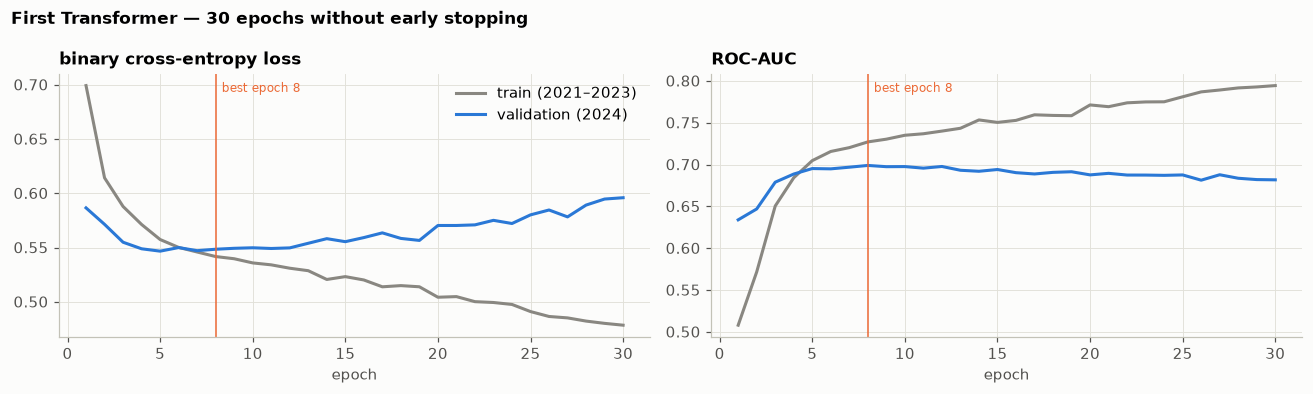

Best validation ROC-AUC 0.699 at epoch 8; after 30 epochs: train AUC 0.794, validation AUC 0.682


In [47]:
keras.utils.set_random_seed(RANDOM_STATE)
first_tf = build_transformer()
first_tf_history = first_tf.fit(T_fit, y_fit, validation_data=(T_val, y_val), epochs=30, batch_size=256, verbose=0)
best = int(np.argmax(first_tf_history.history["val_auc"])) + 1
plot_learning_curves(first_tf_history, "First Transformer — 30 epochs without early stopping", best)
print(f"Best validation ROC-AUC {max(first_tf_history.history['val_auc']):.3f} at epoch {best}; "
      f"after 30 epochs: train AUC {first_tf_history.history['auc'][-1]:.3f}, validation AUC {first_tf_history.history['val_auc'][-1]:.3f}")

The Transformer learns faster than the MLP: the validation ROC-AUC is best (0.699) already in epoch 8. After that the validation loss goes up, the train AUC continues to 0.794 and the validation AUC falls to 0.682 - overfitting again, so early stopping is used in all next runs.

## 10.2 Parameter analysis (one parameter at a time)

Same procedure as for the MLP. The Transformer is about 20 times slower to train, so each setting is trained only once (seed 1) with early stopping (patience 6). The default configuration is trained once and reused in every plot.

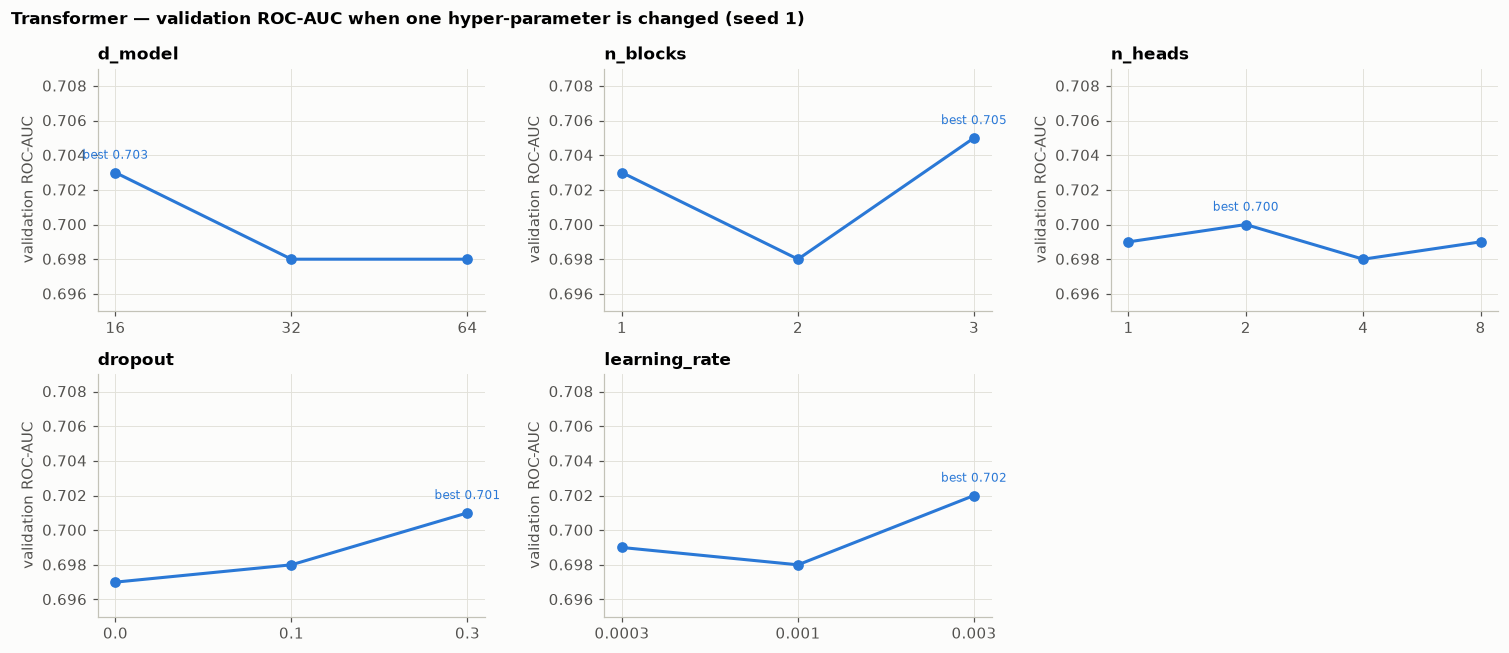

,parameter,value,train,validation,epochs
0,d_model,16,0.772,0.703,18
1,d_model,32,0.757,0.698,12
2,d_model,64,0.752,0.698,7
3,n_blocks,1,0.748,0.703,55
4,n_blocks,2,0.757,0.698,12
5,n_blocks,3,0.788,0.705,12
6,n_heads,1,0.750,0.699,12
7,n_heads,2,0.756,0.700,14
8,n_heads,4,0.757,0.698,12
9,n_heads,8,0.756,0.699,12


In [48]:
TF_DEFAULT = dict(d_model=32, n_blocks=2, n_heads=4, dropout=0.1, learning_rate=1e-3)
TF_GRID_1D = {
    "d_model": [16, 32, 64],
    "n_blocks": [1, 2, 3],
    "n_heads": [1, 2, 4, 8],
    "dropout": [0.0, 0.1, 0.3],
    "learning_rate": [3e-4, 1e-3, 3e-3],
}
tf_cache, tf_rows = {}, []
for param, values in TF_GRID_1D.items():
    for value in values:
        params = {**TF_DEFAULT, param: value}
        key = tuple(sorted(params.items()))
        if key not in tf_cache:                                 # default config is trained only once
            keras.utils.set_random_seed(1)
            model = build_transformer(**params)
            _, best_epoch = train_nn(model, T_fit, y_fit, T_val, y_val, batch_size=256, patience=6)
            tf_cache[key] = (roc_auc_score(y_fit, predict(model, T_fit)), roc_auc_score(y_val, predict(model, T_val)), best_epoch)
        tr_auc, va_auc, epochs_used = tf_cache[key]
        tf_rows.append({"parameter": param, "value": str(value), "train": tr_auc, "validation": va_auc, "epochs": epochs_used})
tf_1d_summary = pd.DataFrame(tf_rows)

plot_1d(tf_1d_summary, 3, "Transformer — validation ROC-AUC when one hyper-parameter is changed (seed 1)")
tf_1d_summary.round(3)

What the plots show (range 0.697-0.705 with one seed, so differences below about 0.004 are mostly noise):
* Number of Transformer blocks: 3 blocks are best (0.705), more attention layers can combine more features.
* Embedding size (`d_model`): a small embedding (16) is as good as 32-64.
* Attention heads: 1-8 heads give almost the same result (0.698-0.700).
* Dropout 0.3 and learning rate 0.003 are a bit better than the defaults.
* How long training takes depends a lot on the architecture (1 block needed 55 epochs, 3 blocks only 12), so early stopping is really needed.

## 10.3 Combined search with KerasTuner (Bayesian optimisation)

In [49]:
def build_transformer_hp(hp):
    return build_transformer(
        d_model=hp.Choice("d_model", [16, 32, 64]),
        n_blocks=hp.Int("n_blocks", 1, 3),
        n_heads=hp.Choice("n_heads", [2, 4, 8]),
        dropout=hp.Choice("dropout", [0.0, 0.1, 0.2, 0.3]),
        learning_rate=hp.Choice("learning_rate", [3e-4, 1e-3, 3e-3]))


tf_tuner = kt.BayesianOptimization(build_transformer_hp, objective=kt.Objective("val_auc", direction="max"), max_trials=12,
                                   num_initial_points=4, seed=RANDOM_STATE, overwrite=True,
                                   directory="keras_tuner_results", project_name="transformer")
tf_tuner.search(T_fit, y_fit, validation_data=(T_val, y_val), epochs=60, batch_size=256, verbose=0,
                callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True)])

trials = [{**t.hyperparameters.values, "validation AUC": t.score} for t in tf_tuner.oracle.trials.values() if t.score is not None]
tf_trials = pd.DataFrame(trials).sort_values("validation AUC", ascending=False)
print(f"{len(tf_trials)} trials finished")
tf_trials.head(10).round(4)

12 trials finished


,d_model,n_blocks,n_heads,dropout,learning_rate,validation AUC
4,32,3,8,0.2,0.0003,0.7061
5,16,2,8,0.1,0.0003,0.7032
3,16,2,2,0.1,0.0010,0.7026
7,16,3,4,0.1,0.0003,0.7023
10,16,3,8,0.1,0.0003,0.7021
6,32,3,8,0.2,0.0003,0.7015
0,32,1,4,0.1,0.0030,0.7014
11,32,2,8,0.2,0.0003,0.7008
2,64,2,8,0.0,0.0030,0.7006
1,32,2,2,0.1,0.0003,0.6991


## 10.4 Model with best parameters

Same as for the MLP: 3 seeds, early stopping on 2024, then training again on 2021-2024 for the chosen number of epochs, and averaging the 3 networks.

Best hyper-parameters: {'d_model': 32, 'n_blocks': 3, 'n_heads': 8, 'dropout': 0.2, 'learning_rate': 0.0003}


Epochs chosen by early stopping (3 seeds): [29, 33, 26]
Trainable parameters: 34,561


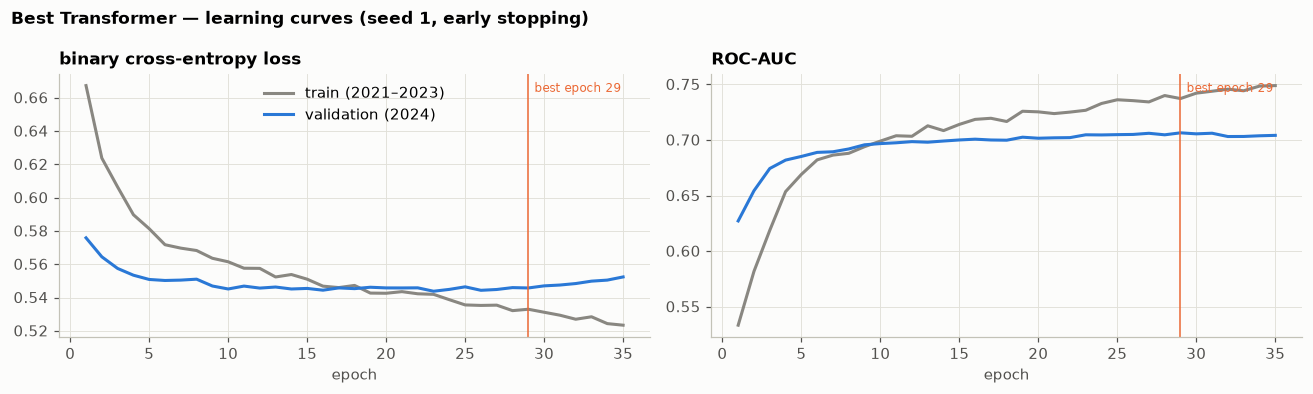

Transformer: decision threshold = 0.28


,ROC-AUC,PR-AUC,accuracy,error rate,balanced accuracy,precision,recall,F1
set,,,,,,,,
train 2021–2024,0.779,0.623,0.706,0.294,0.708,0.503,0.715,0.590
test 2025,0.735,0.520,0.677,0.323,0.668,0.428,0.650,0.516


In [50]:
TF_BEST_HP = tf_tuner.get_best_hyperparameters(1)[0].values
print("Best hyper-parameters:", TF_BEST_HP)

p_val_list, p_train_list, p_test_list, tf_epochs, final_tfs = [], [], [], [], []
for seed in SEEDS:
    keras.utils.set_random_seed(seed)
    model = build_transformer(**TF_BEST_HP)
    history, best_epoch = train_nn(model, T_fit, y_fit, T_val, y_val, batch_size=256, patience=6)
    p_val_list.append(predict(model, T_val))
    tf_epochs.append(best_epoch)
    if seed == SEEDS[0]:
        best_tf_history, best_tf_epoch = history, best_epoch
    keras.utils.set_random_seed(seed)
    final_tf = build_transformer(**TF_BEST_HP)
    final_tf.fit(T_train, y_train, epochs=best_epoch, batch_size=256, verbose=0)
    p_train_list.append(predict(final_tf, T_train))
    p_test_list.append(predict(final_tf, T_test))
    final_tfs.append(final_tf)

print("Epochs chosen by early stopping (3 seeds):", tf_epochs)
print(f"Trainable parameters: {final_tf.count_params():,}")
plot_learning_curves(best_tf_history, "Best Transformer — learning curves (seed 1, early stopping)", best_tf_epoch)

p_val_tf = np.mean(p_val_list, axis=0)
table_tf = store_results("Transformer", np.mean(p_train_list, axis=0), np.mean(p_test_list, axis=0),
                         best_threshold(y_val, p_val_tf), p_val_tf)
table_tf

Result: the best of 12 KerasTuner trials (validation AUC 0.706) has d_model = 32, 3 Transformer blocks, 8 attention heads, dropout 0.2 and learning rate 0.0003 (34 561 trainable parameters). Early stopping chose 26-33 epochs.

On the test year 2025 the Transformer has ROC-AUC = 0.735, the same as the MLP and higher than the random forest (0.728). The train-test gap is 0.044 (train AUC 0.779). With threshold 0.28 it has the best accuracy of the three tuned models (67.7 %, error rate 32.3 %) and finds 65 % of the severe accidents.

# 11. Comparison of the best models

All models were tuned on the same validation year (2024), trained on the same years (2021-2024) and are now compared on the same unseen test year (2025). As a bonus I also add an ensemble: the average probability of the random forest, the MLP and the Transformer.

## 11.1 Accuracy on the training and test sets

In [51]:
# bonus: average of the three tuned models
ens = ["Random forest", "MLP", "Transformer"]
p_val_ens = np.mean([RESULTS[m]["p_val"] for m in ens], axis=0)
store_results("Ensemble (RF + MLP + Transformer)", np.mean([RESULTS[m]["p_train"] for m in ens], axis=0),
              np.mean([RESULTS[m]["p_test"] for m in ens], axis=0), best_threshold(y_val, p_val_ens), p_val_ens)

rows = []
for name, r in RESULTS.items():
    for set_name, y, p in [("train", y_train, r["p_train"]), ("test", y_test, r["p_test"])]:
        rows.append({"model": name, "set": set_name, **evaluate(y, p, r["threshold"])})
comparison = pd.DataFrame(rows).set_index(["model", "set"])
comparison.round(3)

Ensemble (RF + MLP + Transformer): decision threshold = 0.37


ROC-AUC  PR-AUC  accuracy  error rate  balanced accuracy  precision  recall     F1
model                             set                                                                                      
Majority class                    train    0.500   0.297     0.703       0.297              0.500      0.000   0.000  0.000
                                  test     0.500   0.265     0.735       0.265              0.500      0.000   0.000  0.000
Logistic regression               train    0.735   0.541     0.659       0.341              0.670      0.451   0.698  0.548
                                  test     0.727   0.504     0.661       0.339              0.670      0.416   0.690  0.519
Random forest                     train    0.974   0.952     0.891       0.109              0.904      0.756   0.936  0.836
                                  test     0.728   0.513     0.668       0.332              0.654      0.416   0.623  0.499
MLP                               train    0.753   0.572     0.671       0.329              0.685      0.465   0.717  0.564
                                  test     0.735   0.520     0.658       0.342              0.672      0.414   0.701  0.521
Transformer                       train    0.779   0.623     0.706       0.294              0.708      0.503   0.715  0.590
                                  test     0.735   0.520     0.677       0.323              0.668      0.428   0.650  0.516
Ensemble (RF + MLP + Transformer) train    0.849   0.737     0.759       0.241              0.760      0.570   0.761  0.652
                                  test     0.739   0.530     0.685       0.315              0.668      0.435   0.633  0.516

In [52]:
# compact table: test metrics + gap between train and test AUC (overfitting)
test_table = comparison.xs("test", level="set").copy()
test_table.insert(1, "train ROC-AUC", comparison.xs("train", level="set")["ROC-AUC"])
test_table.insert(2, "train − test AUC", test_table["train ROC-AUC"] - test_table["ROC-AUC"])
test_table = test_table.rename(columns={"ROC-AUC": "test ROC-AUC"}).sort_values("test ROC-AUC", ascending=False)
test_table[["test ROC-AUC", "train ROC-AUC", "train − test AUC", "PR-AUC", "accuracy", "error rate",
            "balanced accuracy", "precision", "recall", "F1"]].round(3)

,test ROC-AUC,train ROC-AUC,train − test AUC,PR-AUC,accuracy,error rate,balanced accuracy,precision,recall,F1
model,,,,,,,,,,
Ensemble (RF + MLP + Transformer),0.739,0.849,0.109,0.530,0.685,0.315,0.668,0.435,0.633,0.516
Transformer,0.735,0.779,0.044,0.520,0.677,0.323,0.668,0.428,0.650,0.516
MLP,0.735,0.753,0.018,0.520,0.658,0.342,0.672,0.414,0.701,0.521
Random forest,0.728,0.974,0.246,0.513,0.668,0.332,0.654,0.416,0.623,0.499
Logistic regression,0.727,0.735,0.008,0.504,0.661,0.339,0.670,0.416,0.690,0.519
Majority class,0.500,0.500,0.000,0.265,0.735,0.265,0.500,0.000,0.000,0.000


## 11.2 Statistical test of H1 and H2 (bootstrap)

The test year has 2 802 accidents, so a difference of 0.005 in ROC-AUC could be just luck. To check this I use the bootstrap:
1. take 2 000 random samples of the test accidents with replacement;
2. calculate the ROC-AUC of every model on each sample (the same sample for all models);
3. take the 95 % confidence intervals from these 2 000 results.

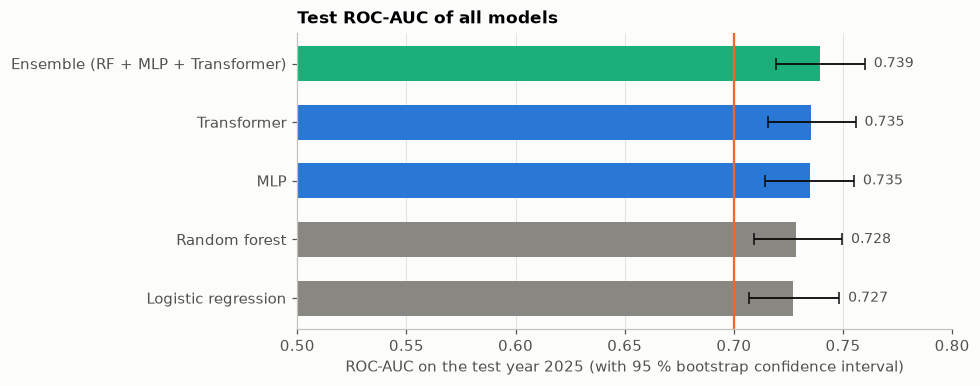

,test ROC-AUC,95% CI low,95% CI high
Logistic regression,0.727,0.707,0.748
Random forest,0.728,0.709,0.750
MLP,0.735,0.714,0.755
Transformer,0.735,0.715,0.756
Ensemble (RF + MLP + Transformer),0.739,0.719,0.760


In [53]:
rng = np.random.default_rng(RANDOM_STATE)
N_BOOT = 2000
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(N_BOOT)]
models_to_test = [m for m in RESULTS if m != "Majority class"]
boot = pd.DataFrame({m: [roc_auc_score(y_test[i], RESULTS[m]["p_test"][i]) for i in boot_idx] for m in models_to_test})

ci = pd.DataFrame({"test ROC-AUC": [roc_auc_score(y_test, RESULTS[m]["p_test"]) for m in models_to_test],
                   "95% CI low": boot.quantile(0.025), "95% CI high": boot.quantile(0.975)}, index=models_to_test)
ci = ci.sort_values("test ROC-AUC")

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [BLUE if m in ("MLP", "Transformer") else (AQUA if m.startswith("Ensemble") else MUTED) for m in ci.index]
ax.barh(ci.index, ci["test ROC-AUC"] - 0.5, left=0.5, color=colors, height=0.6)
ax.errorbar(ci["test ROC-AUC"], np.arange(len(ci)), xerr=[ci["test ROC-AUC"] - ci["95% CI low"], ci["95% CI high"] - ci["test ROC-AUC"]],
            fmt="none", ecolor="#0b0b0b", elinewidth=1.2, capsize=4)
for i, v in enumerate(ci["test ROC-AUC"]):
    ax.text(ci["95% CI high"].iloc[i] + 0.004, i, f"{v:.3f}", va="center", fontsize=9, color=INK2)
ax.axvline(0.70, color=ORANGE, linewidth=1.5)
ax.annotate("H1 threshold 0.70", (0.70, len(ci) - 0.4), xytext=(4, 0), textcoords="offset points", fontsize=8.5, color=ORANGE)
ax.set_xlim(0.5, 0.8)
ax.set_xlabel("ROC-AUC on the test year 2025 (with 95 % bootstrap confidence interval)")
ax.set_title("Test ROC-AUC of all models")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
ci.round(3)

In [54]:
# H2: is a neural network really better than the random forest? paired bootstrap of the AUC difference
rows = []
for nn_name in ["MLP", "Transformer"]:
    diff = boot[nn_name] - boot["Random forest"]
    rows.append({"comparison": f"{nn_name} − Random forest",
                 "AUC difference": roc_auc_score(y_test, RESULTS[nn_name]["p_test"]) - roc_auc_score(y_test, RESULTS["Random forest"]["p_test"]),
                 "95% CI low": diff.quantile(0.025), "95% CI high": diff.quantile(0.975),
                 "P(first model better)": (diff > 0).mean()})
for nn_name in ["MLP", "Transformer", "Random forest"]:
    diff = boot[nn_name] - boot["Logistic regression"]
    rows.append({"comparison": f"{nn_name} − Logistic regression",
                 "AUC difference": roc_auc_score(y_test, RESULTS[nn_name]["p_test"]) - roc_auc_score(y_test, RESULTS["Logistic regression"]["p_test"]),
                 "95% CI low": diff.quantile(0.025), "95% CI high": diff.quantile(0.975),
                 "P(first model better)": (diff > 0).mean()})
h2_table = pd.DataFrame(rows).set_index("comparison")
h2_table["significant (CI excludes 0)"] = np.where((h2_table["95% CI low"] > 0) | (h2_table["95% CI high"] < 0), "yes", "no")
h2_table.round(3)

,AUC difference,95% CI low,95% CI high,P(first model better),significant (CI excludes 0)
comparison,,,,,
MLP − Random forest,0.006,-0.005,0.018,0.879,no
Transformer − Random forest,0.007,-0.005,0.018,0.880,no
MLP − Logistic regression,0.008,0.003,0.012,1.000,yes
Transformer − Logistic regression,0.008,0.000,0.016,0.976,yes
Random forest − Logistic regression,0.001,-0.011,0.014,0.568,no


## 11.3 ROC curves and confusion matrices (test year 2025)

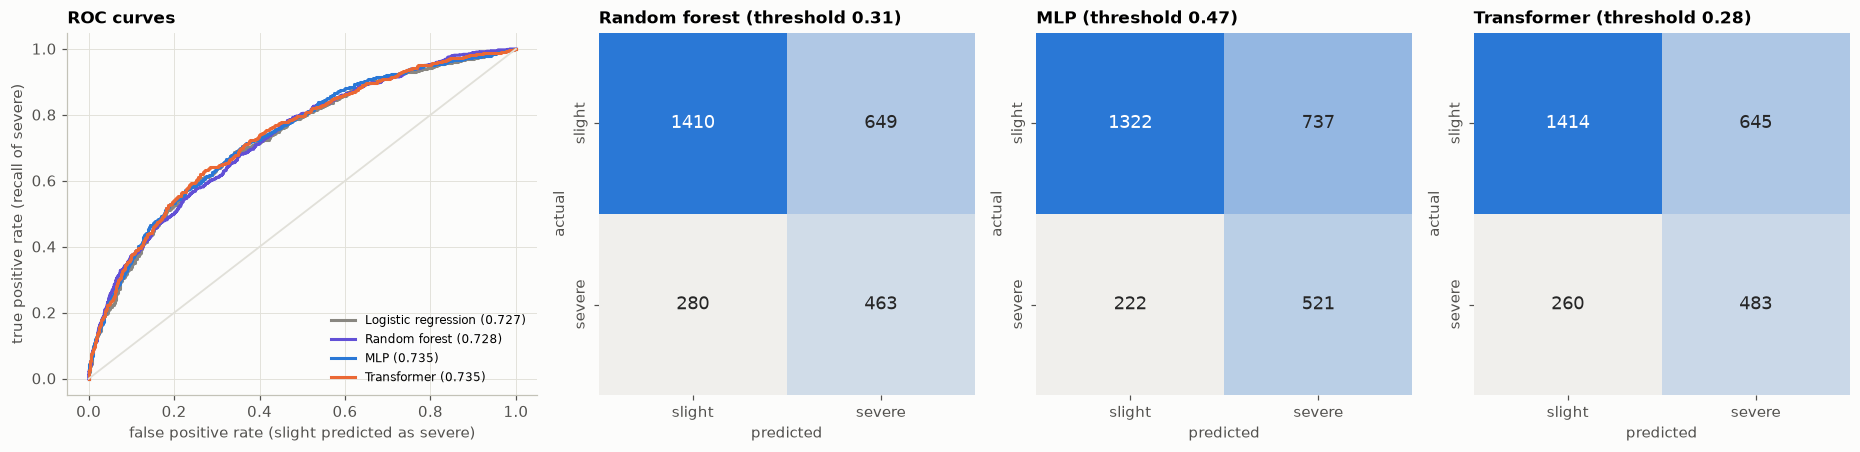

In [55]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.25, 1, 1, 1]})
ax = axes[0]
for name, color in [("Logistic regression", MUTED), ("Random forest", VIOLET), ("MLP", BLUE), ("Transformer", ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test, RESULTS[name]["p_test"])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} ({roc_auc_score(y_test, RESULTS[name]['p_test']):.3f})")
ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.2)
ax.set_xlabel("false positive rate (slight predicted as severe)")
ax.set_ylabel("true positive rate (recall of severe)")
ax.set_title("ROC curves")
ax.legend(loc="lower right", fontsize=8)

cmap = mcolors.LinearSegmentedColormap.from_list("b", ["#f0efec", BLUE])
for ax, name in zip(axes[1:], ["Random forest", "MLP", "Transformer"]):
    r = RESULTS[name]
    cm = confusion_matrix(y_test, (r["p_test"] >= r["threshold"]).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, xticklabels=["slight", "severe"],
                yticklabels=["slight", "severe"], ax=ax, annot_kws={"size": 12})
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(f"{name} (threshold {r['threshold']:.2f})")
plt.tight_layout()
plt.show()

## 11.4 Which circumstances matter most? (permutation importance)

Permutation importance: I shuffle the values of one feature between the test accidents and measure how much the test ROC-AUC drops. If it drops a lot, the model really uses this feature. This works the same way for every model, so the random forest and the neural networks can be compared. Each feature is shuffled 3 times.

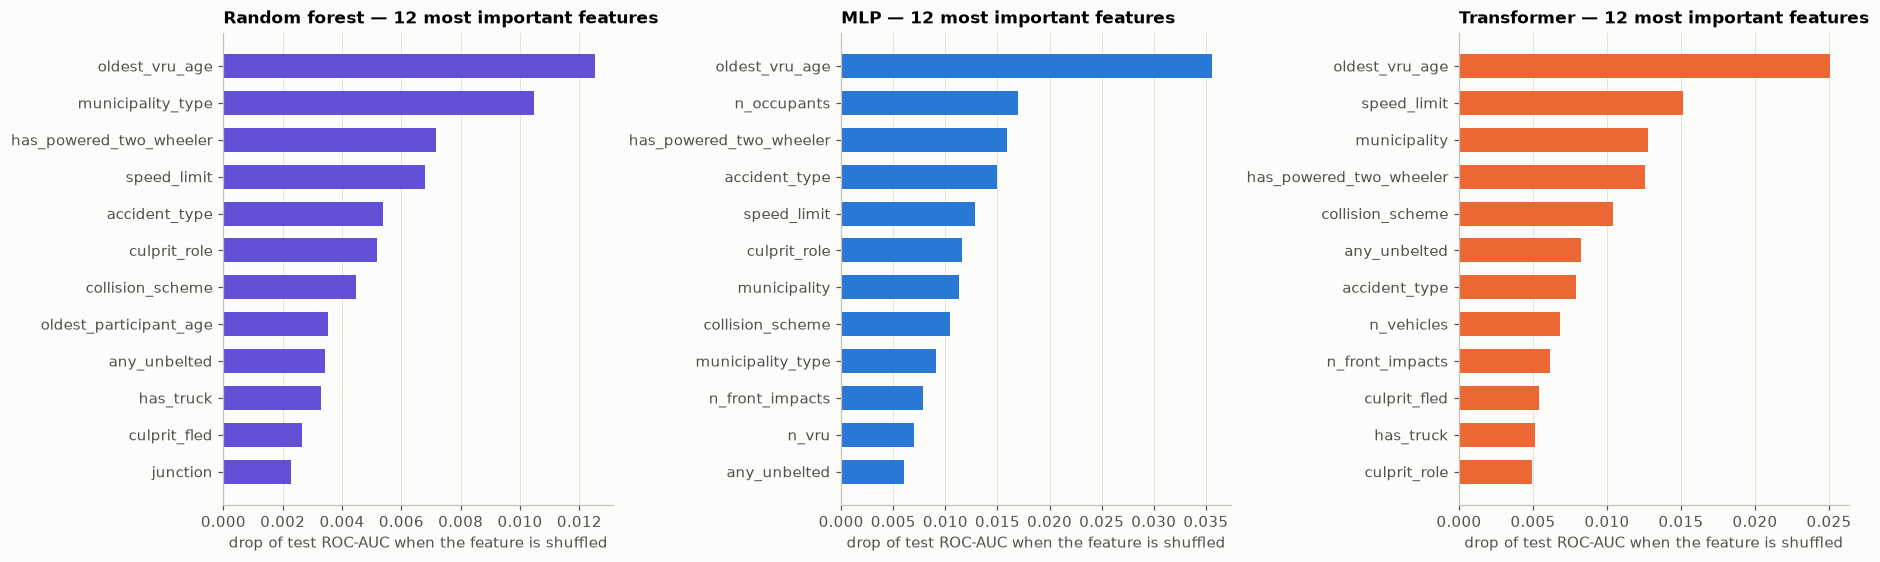

,Random forest,MLP,Transformer,mean
oldest_vru_age,0.0125,0.0356,0.0251,0.0244
has_powered_two_wheeler,0.0072,0.0159,0.0126,0.0119
speed_limit,0.0068,0.0129,0.0151,0.0116
accident_type,0.0054,0.0149,0.0079,0.0094
collision_scheme,0.0045,0.0105,0.0104,0.0085
municipality,0.0004,0.0113,0.0128,0.0082
culprit_role,0.0052,0.0116,0.0049,0.0072
municipality_type,0.0105,0.0091,0.0020,0.0072
n_occupants,-0.0001,0.0169,0.0034,0.0067
any_unbelted,0.0034,0.0060,0.0083,0.0059


In [56]:
def permutation_importance_auc(predict_fn, data, n_repeats=3):
    base = roc_auc_score(y_test, predict_fn(data))
    rng_pi = np.random.default_rng(RANDOM_STATE)
    drops = {}
    for col in NUM_FEATURES + BIN_FEATURES + CAT_FEATURES:
        cols = [f"{col}_sin", f"{col}_cos"] if col in ("hour", "month", "weekday") else [col]   # shuffle sin and cos together
        scores = []
        for _ in range(n_repeats):
            shuffled = data.copy()
            perm = rng_pi.permutation(len(data))
            shuffled[cols] = data[cols].to_numpy()[perm]
            scores.append(roc_auc_score(y_test, predict_fn(shuffled)))
        drops[col] = base - np.mean(scores)
    return pd.Series(drops).sort_values()


imp_rf = permutation_importance_auc(lambda d: rf_model.predict_proba(d[X_COLS])[:, 1], test_df)
# neural networks = average of 3 seeds, same as in the comparison table
imp_mlp = permutation_importance_auc(
    lambda d: np.mean([predict(m, mlp_prep_full.transform(d[X_COLS]).astype("float32")) for m in final_mlps], axis=0), test_df)
imp_tf = permutation_importance_auc(
    lambda d: np.mean([predict(m, transformer_inputs(d)) for m in final_tfs], axis=0), test_df)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, (name, imp, color) in zip(axes, [("Random forest", imp_rf, VIOLET), ("MLP", imp_mlp, BLUE), ("Transformer", imp_tf, ORANGE)]):
    top = imp.tail(12)
    ax.barh(top.index, top.values, color=color, height=0.65)
    ax.set_title(f"{name} — 12 most important features")
    ax.set_xlabel("drop of test ROC-AUC when the feature is shuffled")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

importance = pd.DataFrame({"Random forest": imp_rf, "MLP": imp_mlp, "Transformer": imp_tf})
importance["mean"] = importance.mean(axis=1)
importance.sort_values("mean", ascending=False).head(15).round(4)

## 11.5 A closer look at the most important feature

All three models agree that the age of the oldest vulnerable road user (pedestrian, cyclist, motorcycle / moped / e-scooter rider) is the most important feature. I added this feature after the interim presentation. The plot shows why it matters (training years only, the grey line is the overall severe share).

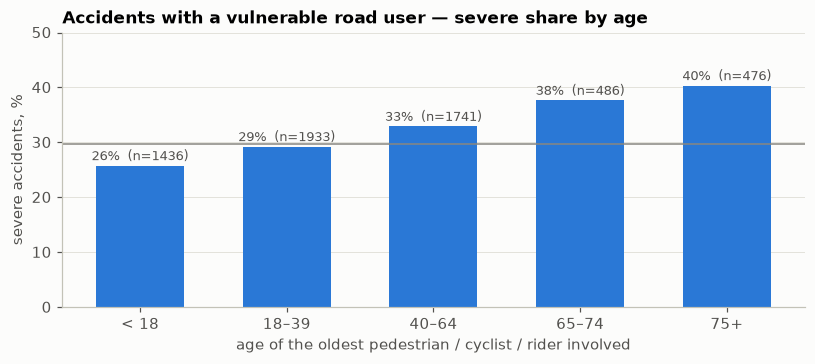

,severe_share,accidents
oldest VRU age,,
< 18,0.258,1436
18–39,0.292,1933
40–64,0.329,1741
65–74,0.377,486
75+,0.403,476


In [57]:
# why is oldest_vru_age so important? severe share by age of the oldest VRU (training years)
vru = tr[tr["n_vru"] > 0].copy()
vru["oldest VRU age"] = pd.cut(vru["oldest_vru_age"], [-1, 17, 39, 64, 74, 120],
                               labels=["< 18", "18–39", "40–64", "65–74", "75+"])
age_table = vru.groupby("oldest VRU age", observed=True)[TARGET].agg(severe_share="mean", accidents="size")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(age_table.index.astype(str), age_table["severe_share"] * 100, color=BLUE, width=0.6)
for i, (share_, n) in enumerate(zip(age_table["severe_share"], age_table["accidents"])):
    ax.text(i, share_ * 100 + 1, f"{share_:.0%}  (n={n})", ha="center", fontsize=8.5, color=INK2)
ax.axhline(overall * 100, color=MUTED, linewidth=1)          # overall severe share
ax.set_ylim(0, 50)
ax.set_xlabel("age of the oldest pedestrian / cyclist / rider involved")
ax.set_ylabel("severe accidents, %")
ax.set_title("Accidents with a vulnerable road user — severe share by age")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
age_table.round(3)

### Summary of the comparison

| Model | Test ROC-AUC (95 % CI) | Train ROC-AUC | Train - test | Test recall (severe) | Test accuracy |
|---|---|---|---|---|---|
| Ensemble (RF + MLP + Transformer) | 0.739 (0.719-0.760) | 0.849 | 0.11 | 0.63 | 0.685 |
| Transformer | 0.735 (0.715-0.756) | 0.779 | 0.04 | 0.65 | 0.677 |
| MLP | 0.735 (0.714-0.755) | 0.753 | 0.02 | 0.70 | 0.658 |
| Random forest | 0.728 (0.709-0.750) | 0.974 | 0.25 | 0.62 | 0.668 |
| Logistic regression | 0.727 (0.707-0.748) | 0.735 | 0.01 | 0.69 | 0.661 |
| Majority class | 0.500 | 0.500 | 0 | 0.00 | 0.735 |

* H1 is accepted. All models are above 0.70 on the unseen year 2025, and even the lower end of every 95 % confidence interval is above 0.70. So severity can be predicted from the circumstances clearly better than chance.
* H2 is not confirmed statistically. Both neural networks are better than the random forest (+0.006 / +0.007 ROC-AUC, better in 88 % of the bootstrap samples), but the 95 % confidence interval of the difference includes 0, so the advantage could be random. Compared with logistic regression the MLP (+0.008, CI 0.003-0.012) and the Transformer (+0.008) are significantly better, so the networks do learn some non-linear structure, but the gain is small.
* Overfitting: the random forest memorises the training data (train 0.97, test 0.73). The neural networks with early stopping, dropout and L2 generalise much better (gap 0.02-0.04).
* Accuracy alone is misleading: the majority class has the highest accuracy (73.5 %) but finds no severe accidents at all. The real models give up some accuracy to find 62-70 % of the severe accidents.
* Ensemble: averaging the three models gives the best test ROC-AUC (0.739), because the models make partly different mistakes.
* Most important circumstances (permutation importance, similar for all three models): the age of the oldest vulnerable road user is clearly the most important feature (26 % severe when the oldest pedestrian / cyclist / rider is under 18, 40 % when 75 or older, see 11.5), then powered two-wheelers, the speed limit, the type of accident / collision scheme, the municipality (countryside vs city) and seat belt use.

# 12. Conclusions

1. Dataset. I used the official Lithuanian Police data from data.gov.lt (2021-2025). From 108 918 accident records in nested JSON I made 14 049 injury accidents with 59 features without leakage, and the target killed or seriously injured (29 %). During preparation I fixed real problems in the data: wrong dates (one record from 1899), impossible speed limits (0-8, 140 and 500 km/h), placeholder, out-of-country and misplaced coordinates, impossible ages, two spellings of the same municipality, missing values and extreme counts.
2. H1 is accepted. All models predict severity clearly better than chance on the unseen year 2025: ROC-AUC 0.727-0.739, and the lower bounds of all 95 % confidence intervals are above 0.70.
3. H2 is not confirmed. The MLP and the Transformer (both 0.735) are better than the random forest (0.728) and significantly better than logistic regression (0.727), but the difference to the random forest is within the statistical uncertainty. This is similar to what research on tabular data shows (Grinsztajn et al., 2022): neural networks rarely beat tree ensembles by much. But the neural networks generalise much better (train-test gap 0.02-0.04 vs 0.25 for the random forest), and the ensemble of all three models was the best (0.739).
4. H1a-H1e are supported (chi-square tests, p < 0.001): speed limit >= 70 km/h and darkness without street lights increase the risk of a severe outcome by about 70 %, an intoxicated culprit and no seat belt by about 50 %, a vulnerable road user by 10 %.
5. Most important circumstances: the age of the oldest pedestrian / cyclist / rider, motorcycles and mopeds, the speed limit (roads in the countryside), the type of crash (run-off-road, head-on, rollover), the municipality and seat belt use. In practice this means safer crossings and better lighting for elderly pedestrians, speed control on regional roads and seat belt checks.
6. Parameter analysis. For the neural networks the hyperparameters changed the validation ROC-AUC by less than 0.01, much less than good features: the features I added after the interim presentation (ages of vulnerable road users, number of occupants, trucks) became the most important inputs for all models. Early stopping and regularisation were really needed, because every network started to overfit after 8-40 epochs.
7. Evaluation. Training on the past and testing on the next year, removing all outcome fields (with them the score would go up to 0.785, see 7.4), using ROC-AUC instead of accuracy (the useless majority model has 73.5 % accuracy) and testing the differences statistically make the results trustworthy.

Limitations and future work: the police data doesn't have the most direct causes of injury severity (impact speed, safety rating of the car, body position, ambulance time), so part of the outcome stays random, and this limits all models to ROC-AUC around 0.74. Next steps could be: using all years 2013-2025 (about 3 times more data), calibrating the probabilities, visualising the attention of the Transformer to explain single predictions, and adding road data (traffic volume, road width).